# Hydro, Wind, Solar, Biomass and Geothermal Energy in the Southern U.S. Region
## Review 2: Forecasting (separate models for each resource)

**Research question:** How do hydro, wind, solar, biomass and geothermal electricity generation vary over time in the Southern U.S. region, and
what specific trends, seasonal cycles and temporal dependencies can be isolated to accurately forecast their future contributions?

A **separate set of models is built for each resource** (hydro, wind, solar, biomass), because Review 1 showed that each has its own trend,
seasonality and stationarity behaviour. Geothermal generation is zero in every month in the South, so no model is needed (section 11).

| Step | Models |
|---|---|
| Baseline | Naive, Seasonal Naive |
| Classical | ARIMA (with differencing), SARIMA, SARIMAX |
| Exponential smoothing | SES, Holt, Holt-Winters additive / multiplicative |
| Machine learning | Linear Regression, Random Forest |
| Neural network | Multi-layer perceptron (scikit-learn `MLPRegressor`) |

## 1. Setup and data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing, Holt
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

In [2]:
# Path to the dataset (on Colab: upload the CSV and change this path, e.g. "/content/usa_state_renewable_monthly_2001_2026.csv")
DATA_PATH = "../data/usa_state_renewable_monthly_2001_2026.csv"

df = pd.read_csv(DATA_PATH)
df["month"] = pd.to_datetime(df["month"])

region_df = df[df["census_region"] == "South"].copy()

# The file has one row per state per month -> add the Southern states together to get one value per month
region = (
    region_df
    .groupby("month")[["hydro", "wind", "solar", "biomass", "geothermal"]]
    .sum()
    .asfreq("MS")
)

RESOURCES = ["hydro", "wind", "solar", "biomass"]          # geothermal is excluded (always 0 in the South, see Review 1)
SOLAR_START = "2010-01-01"                          # solar is ~0 before 2010 (see Review 1)

series = {
    "hydro":   region["hydro"],
    "wind":    region["wind"],
    "solar":   region["solar"].loc[SOLAR_START:],
    "biomass": region["biomass"],
}
for r in RESOURCES:
    print(f"{r:8s}: {series[r].index.min():%b %Y} - {series[r].index.max():%b %Y}, {len(series[r])} months")

hydro   : Jan 2001 - Jul 2026, 307 months
wind    : Jan 2001 - Jul 2026, 307 months
solar   : Jan 2010 - Jul 2026, 199 months
biomass : Jan 2001 - Jul 2026, 307 months


## 2. Train / Test Split

* The split is **chronological**: the model only ever sees the past. Shuffling is not used, because it would let the model learn from future months.
* **Test set = the last 24 months (Aug 2024 – Jul 2026)**. That is two full seasonal cycles, so each calendar month is tested twice.
* Training = everything before Aug 2024. That is 283 months for hydro, wind and biomass and 175 months for solar.
* Every model forecasts all 24 test months **from the end of the training data** (multi-step forecasting). This is how the model would be used in practice.

In [3]:
TEST_MONTHS = 24
H_FUTURE = 12          # final forecast horizon after the evaluation

train, test = {}, {}
for r in RESOURCES:
    train[r] = series[r].iloc[:-TEST_MONTHS]
    test[r] = series[r].iloc[-TEST_MONTHS:]
    print(f"{r:8s}: train {train[r].index.min():%b %Y}-{train[r].index.max():%b %Y} ({len(train[r])}), "
          f"test {test[r].index.min():%b %Y}-{test[r].index.max():%b %Y} ({len(test[r])})")

hydro   : train Jan 2001-Jul 2024 (283), test Aug 2024-Jul 2026 (24)
wind    : train Jan 2001-Jul 2024 (283), test Aug 2024-Jul 2026 (24)
solar   : train Jan 2010-Jul 2024 (175), test Aug 2024-Jul 2026 (24)
biomass : train Jan 2001-Jul 2024 (283), test Aug 2024-Jul 2026 (24)


## 3. Accuracy metrics

* **MAE**: average absolute error (GWh).
* **RMSE**: like MAE, but penalises large errors more (GWh).
* **MAPE**: average absolute percentage error (%). It is scale-free, so the three resources can be compared.
* **MASE**: MAE divided by the in-sample error of the seasonal naive forecast. **MASE < 1** means better than a naive seasonal forecast on the training data.

In [4]:
def evaluate(actual, forecast, train_series):
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    error = actual - forecast
    naive_scale = np.mean(np.abs(train_series.values[12:] - train_series.values[:-12]))
    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE": np.mean(np.abs(error / actual)) * 100,
        "MASE": np.mean(np.abs(error)) / naive_scale,
    }

## 4. Model functions

Every model is a function `model(train_series, h)` that returns `h` future values. That way the **same** functions are applied
to each resource, and the best model can be re-fitted on all the data for the final forecast.

**Transformation.** As in Review 1, a resource whose seasonal swings grow with its level (correlation between the 12-month rolling mean
and rolling std > 0.7) is modelled on the **log scale** by the ARIMA, SARIMA, SARIMAX and ML models, and converted back with `exp()`.
The other resources are modelled on their original scale.

In [5]:
USE_LOG = {r: bool(train[r].rolling(12).mean().corr(train[r].rolling(12).std()) > 0.7) for r in RESOURCES}
print("Log scale used for:", USE_LOG)

def to_model_scale(y, r):
    return np.log(y) if USE_LOG[r] else y

def from_model_scale(z, r):
    return np.exp(z) if USE_LOG[r] else z

# ---------------- Baselines ----------------
def naive_forecast(y, h, r=None):
    """Every future month = the last observed month."""
    return np.repeat(y.iloc[-1], h)

def seasonal_naive_forecast(y, h, r=None):
    """Every future month = the same month one year earlier."""
    last_year = y.iloc[-12:].values
    return np.array([last_year[i % 12] for i in range(h)])

Log scale used for: {'hydro': False, 'wind': True, 'solar': True, 'biomass': False}


### Choosing the differencing orders (d, D) from the training data
The rule is the same as in Review 1. Use a seasonal difference (D = 1) when seasonal strength > 0.64. Then add a first difference (d = 1) if ADF and KPSS still disagree with stationarity.

In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose

def choose_differencing(z):
    d_parts = seasonal_decompose(z, model="additive", period=12)
    resid, seas = d_parts.resid.dropna(), d_parts.seasonal[d_parts.resid.notna()]
    seasonal_strength = max(0, 1 - resid.var() / (seas + resid).var())
    D = 1 if seasonal_strength > 0.64 else 0
    x = z.diff(12).dropna() if D else z
    adf_p = adfuller(x)[1]
    kpss_p = kpss(x, regression="c", nlags="auto")[1]
    d = 0 if (adf_p < 0.05 and kpss_p > 0.05) else 1
    return d, D, seasonal_strength, adf_p, kpss_p

diff_orders = {}
rows = []
for r in RESOURCES:
    d, D, fs, adf_p, kpss_p = choose_differencing(to_model_scale(train[r], r))
    diff_orders[r] = (d, D)
    rows.append({"resource": r, "seasonal_strength": fs, "D": D, "ADF p (after D)": adf_p,
                 "KPSS p (after D)": kpss_p, "d": d})
pd.DataFrame(rows).set_index("resource")

,seasonal_strength,D,ADF p (after D),KPSS p (after D),d
resource,,,,,
hydro,0.406,0,0.016,0.083,0
wind,0.537,0,0.005,0.010,1
solar,0.682,1,0.615,0.010,1
biomass,0.661,1,0.061,0.038,1


### ARIMA / SARIMA / SARIMAX order selection (AIC grid search on the training data)

In [7]:
def trend_term(d, D):
    # A drift (linear trend) is only meaningful when the total amount of differencing is 1
    return ["n", "t"] if d + D == 1 else (["n", "c"] if d + D == 0 else ["n"])

def grid_search(z, d, D, seasonal, exog=None):
    results = []
    pq = range(0, 3) if seasonal else range(0, 4)
    PQ = range(0, 2) if seasonal else [0]
    for p, q, P, Q in itertools.product(pq, pq, PQ, PQ):
        for t in trend_term(d, D if seasonal else 0):
            seasonal_order = (P, D, Q, 12) if seasonal else (0, 0, 0, 0)
            try:
                fit = ARIMA(z, exog=exog, order=(p, d, q), seasonal_order=seasonal_order, trend=t).fit()
                resid = fit.resid.iloc[d + 12 * seasonal_order[1] + 1:]
                # reject failed / degenerate fits: the residuals of a sensible model are centred near 0
                # and smaller than the series itself (a broken fit can report a meaninglessly low AIC)
                if not np.isfinite(fit.aic) or abs(resid.mean()) > 0.5 * z.std() or resid.std() > z.std():
                    continue
                results.append({"order": (p, d, q), "seasonal_order": seasonal_order, "trend": t, "AIC": fit.aic})
            except Exception:
                pass
    return pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)

# SARIMAX exogenous variables: Fourier terms (sin/cos of the month) and a time index.
# They are known in advance for any future month, so there is NO data leakage.
# (Hydro, solar, biomass of the same month cannot be used to predict each other: they are not known in the future.)
def fourier_exog(index, start, with_time=True):
    t = ((index.year - start.year) * 12 + (index.month - start.month)).values + 1
    month = index.month.values
    X = pd.DataFrame({
        "sin1": np.sin(2 * np.pi * month / 12), "cos1": np.cos(2 * np.pi * month / 12),
        "sin2": np.sin(4 * np.pi * month / 12), "cos2": np.cos(4 * np.pi * month / 12),
    }, index=index)
    if with_time:          # a time index is only added when the series is NOT differenced (differencing removes it)
        X.insert(0, "time", t)
    return X

In [8]:
orders = {}
for r in RESOURCES:
    z = to_model_scale(train[r], r)
    d, D = diff_orders[r]
    # non-seasonal differencing order for ARIMA / SARIMAX: d=1 unless the series itself is already stationary
    d_ns = 0 if (adfuller(z)[1] < 0.05 and kpss(z, regression="c", nlags="auto")[1] > 0.05) else 1
    arima_grid = grid_search(z, d_ns, 0, seasonal=False)
    sarima_grid = grid_search(z, d, D, seasonal=True)
    X = fourier_exog(z.index, z.index[0], with_time=(d_ns == 0))
    sarimax_grid = grid_search(z, d_ns, 0, seasonal=False, exog=X)                # ARIMA errors + Fourier (+ time) regressors
    orders[r] = {"ARIMA": arima_grid.iloc[0].to_dict(), "SARIMA": sarima_grid.iloc[0].to_dict(),
                 "SARIMAX": sarimax_grid.iloc[0].to_dict()}
    print(f"===== {r.upper()} =====")
    print("Top 3 SARIMA models by AIC:")
    print(sarima_grid.head(3).to_string(index=False))
    for k, v in orders[r].items():
        print(f"  selected {k:8s}: order={v['order']}, seasonal={v['seasonal_order']}, trend={v['trend']}, AIC={v['AIC']:.1f}")
    print()

===== HYDRO =====
Top 3 SARIMA models by AIC:
    order seasonal_order trend      AIC
(1, 0, 0)  (1, 0, 1, 12)     c 4543.161
(2, 0, 0)  (1, 0, 1, 12)     c 4545.089
(1, 0, 1)  (1, 0, 1, 12)     c 4545.677
  selected ARIMA   : order=(3, 0, 2), seasonal=(0, 0, 0, 0), trend=c, AIC=4570.2
  selected SARIMA  : order=(1, 0, 0), seasonal=(1, 0, 1, 12), trend=c, AIC=4543.2
  selected SARIMAX : order=(3, 0, 2), seasonal=(0, 0, 0, 0), trend=c, AIC=4541.9



===== WIND =====
Top 3 SARIMA models by AIC:
    order seasonal_order trend      AIC
(1, 1, 1)  (1, 0, 1, 12)     n -160.048
(1, 1, 1)  (1, 0, 1, 12)     t -160.010
(2, 1, 1)  (1, 0, 1, 12)     t -159.560
  selected ARIMA   : order=(3, 1, 2), seasonal=(0, 0, 0, 0), trend=t, AIC=-97.6
  selected SARIMA  : order=(1, 1, 1), seasonal=(1, 0, 1, 12), trend=n, AIC=-160.0
  selected SARIMAX : order=(0, 1, 1), seasonal=(0, 0, 0, 0), trend=t, AIC=-185.7



===== SOLAR =====
Top 3 SARIMA models by AIC:
    order seasonal_order trend     AIC
(1, 1, 0)  (0, 1, 1, 12)     n -87.594
(1, 1, 0)  (1, 1, 1, 12)     n -87.417
(2, 1, 2)  (1, 1, 1, 12)     n -86.412
  selected ARIMA   : order=(3, 1, 2), seasonal=(0, 0, 0, 0), trend=n, AIC=-74.2
  selected SARIMA  : order=(1, 1, 0), seasonal=(0, 1, 1, 12), trend=n, AIC=-87.6
  selected SARIMAX : order=(0, 1, 3), seasonal=(0, 0, 0, 0), trend=t, AIC=-115.6



===== BIOMASS =====
Top 3 SARIMA models by AIC:
    order seasonal_order trend      AIC
(0, 1, 1)  (0, 1, 1, 12)     n 3127.700
(0, 1, 1)  (1, 1, 1, 12)     n 3129.496
(2, 1, 0)  (0, 1, 1, 12)     n 3129.544
  selected ARIMA   : order=(2, 1, 3), seasonal=(0, 0, 0, 0), trend=n, AIC=3449.5
  selected SARIMA  : order=(0, 1, 1), seasonal=(0, 1, 1, 12), trend=n, AIC=3127.7
  selected SARIMAX : order=(0, 1, 3), seasonal=(0, 0, 0, 0), trend=n, AIC=3406.5



In [9]:
def make_arima(kind):
    def model(y, h, r):
        o = orders[r][kind]
        z = to_model_scale(y, r)
        if kind == "SARIMAX":
            with_time = o["order"][1] == 0
            X = fourier_exog(z.index, series[r].index[0], with_time)
            future_index = pd.date_range(z.index[-1] + pd.offsets.MonthBegin(), periods=h, freq="MS")
            X_future = fourier_exog(future_index, series[r].index[0], with_time)
            fit = ARIMA(z, exog=X, order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
            return from_model_scale(fit.forecast(h, exog=X_future).values, r)
        fit = ARIMA(z, order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
        return from_model_scale(fit.forecast(h).values, r)
    return model

### Holt-Winters / exponential smoothing

In [10]:
def ses_forecast(y, h, r=None):
    return SimpleExpSmoothing(y, initialization_method="estimated").fit().forecast(h).values

def holt_forecast(y, h, r=None):
    return Holt(y, damped_trend=True, initialization_method="estimated").fit().forecast(h).values

def make_hw(seasonal, damped):
    def model(y, h, r=None):
        fit = ExponentialSmoothing(y, trend="add", damped_trend=damped, seasonal=seasonal,
                                   seasonal_periods=12, initialization_method="estimated").fit()
        return fit.forecast(h).values
    return model

### Machine learning and neural network

**Features** are all built from past values only:
* lag_1, lag_2, lag_3, lag_6, lag_12;
* rolling_mean_3, rolling_mean_6, rolling_mean_12;
* month (as sin/cos), quarter.

**Target.** Tree models cannot predict values higher than anything they have seen, and solar keeps reaching new highs. The ML models therefore predict the
**change from the same month last year**, w(t) = z(t) − z(t−12), where z is the (log) series. The forecast is rebuilt as z(t) = z(t−12) + w(t).

**Forecasting.** Multi-step forecasts are made **recursively**: each prediction is fed back in as a lag for the next month.

In [11]:
LAGS = [1, 2, 3, 6, 12]

def make_features(w_history, month):
    row = {f"lag_{k}": w_history[-k] for k in LAGS}
    for win in (3, 6, 12):
        row[f"rolling_mean_{win}"] = np.mean(w_history[-win:])
    row["month_sin"] = np.sin(2 * np.pi * month / 12)
    row["month_cos"] = np.cos(2 * np.pi * month / 12)
    row["quarter"] = (month - 1) // 3 + 1
    return row

def build_training_table(y, r):
    z = to_model_scale(y, r)
    w = (z - z.shift(12)).dropna()
    rows, targets = [], []
    for i in range(12, len(w)):
        rows.append(make_features(list(w.values[:i]), w.index[i].month))
        targets.append(w.values[i])
    return pd.DataFrame(rows), np.array(targets)

def make_ml(estimator_factory):
    def model(y, h, r):
        X, target = build_training_table(y, r)
        est = estimator_factory().fit(X, target)
        z = list(to_model_scale(y, r).values)
        w = list((to_model_scale(y, r) - to_model_scale(y, r).shift(12)).dropna().values)
        month = y.index[-1].month
        out = []
        for _ in range(h):
            month = month % 12 + 1
            w_hat = est.predict(pd.DataFrame([make_features(w, month)]))[0]
            z_new = z[-12] + w_hat
            w.append(w_hat); z.append(z_new); out.append(z_new)
        return from_model_scale(np.array(out), r)
    return model

linear_model = make_ml(lambda: LinearRegression())
forest_model = make_ml(lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42))
mlp_model = make_ml(lambda: make_pipeline(StandardScaler(),
                                          MLPRegressor(hidden_layer_sizes=(16, 8), alpha=0.01, max_iter=3000,
                                                       early_stopping=True, random_state=42)))

**Why a small MLP and not an LSTM/GRU?** Each resource has only 175–283 training months, which gives about 150–260 training rows.
That is far too few for recurrent deep-learning models, which have thousands of parameters and would overfit.
A small feed-forward neural network (16 and 8 hidden units, L2 penalty, early stopping) is the most complex network these data can support.

In [12]:
MODELS = {
    "Naive":                    ("Baseline", naive_forecast),
    "Seasonal Naive":           ("Baseline", seasonal_naive_forecast),
    "ARIMA":                    ("ARIMA", make_arima("ARIMA")),
    "SARIMA":                   ("SARIMA", make_arima("SARIMA")),
    "SARIMAX (Fourier exog)":  ("SARIMAX", make_arima("SARIMAX")),
    "SES":                      ("Exponential smoothing", ses_forecast),
    "Holt (damped)":            ("Exponential smoothing", holt_forecast),
    "Holt-Winters additive":    ("Holt-Winters", make_hw("add", False)),
    "Holt-Winters multiplicative": ("Holt-Winters", make_hw("mul", False)),
    "Holt-Winters add. damped": ("Holt-Winters", make_hw("add", True)),
    "Linear Regression":        ("ML", linear_model),
    "Random Forest":            ("ML", forest_model),
    "Neural Network (MLP)":     ("Neural network", mlp_model),
}

def run_all_models(r):
    forecasts, rows = {}, []
    for name, (family, fn) in MODELS.items():
        fc = np.asarray(fn(train[r], TEST_MONTHS, r), float)
        forecasts[name] = pd.Series(fc, index=test[r].index)
        rows.append({"model": name, "family": family, **evaluate(test[r], fc, train[r])})
    table = pd.DataFrame(rows).set_index("model").sort_values("MASE")
    return forecasts, table

def plot_forecasts(r, forecasts, table, top=5):
    plt.figure(figsize=(15, 6))
    plt.plot(series[r].loc["2019-01-01":], color="black", linewidth=2, label="Actual")
    plt.axvline(test[r].index[0], color="gray", linestyle=":", label="Start of test period")
    for name in ["Seasonal Naive"] + [m for m in table.index if m != "Seasonal Naive"][:top]:
        plt.plot(forecasts[name], linewidth=1.5, label=f"{name} (MAPE {table.loc[name, 'MAPE']:.1f}%)")
    plt.title(f"{r.capitalize()}: test-period forecasts (Aug 2024 - Jul 2026)")
    plt.ylabel("GWh")
    plt.legend(fontsize=9)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def residual_analysis(r, model_name):
    """In-sample residuals cannot be computed the same way for every model, so we analyse
    one-step-ahead errors over the last 60 training months plus the 24 test-period errors."""
    fn = MODELS[model_name][1]
    y = series[r]
    test_errors = test[r] - all_forecasts[r][model_name]
    # rolling one-step-ahead errors on the 60 months before the test period
    one_step = []
    for t in range(len(train[r]) - 60, len(train[r])):
        one_step.append(y.iloc[t] - fn(y.iloc[:t], 1, r)[0])
    one_step = pd.Series(one_step, index=y.index[len(train[r]) - 60:len(train[r])])
    return one_step, test_errors

def residual_report(r, model_name, residuals):
    fig, axes = plt.subplots(2, 2, figsize=(15, 8))
    axes[0, 0].plot(residuals, marker=".")
    axes[0, 0].axhline(0, color="red")
    axes[0, 0].set_title("Residuals over time")
    plot_acf(residuals, lags=min(24, len(residuals) // 2 - 1), ax=axes[0, 1])
    axes[0, 1].set_title("ACF of residuals")
    axes[1, 0].hist(residuals, bins=15, edgecolor="black")
    axes[1, 0].set_title("Distribution of residuals")
    stats.probplot(residuals, dist="norm", plot=axes[1, 1])
    axes[1, 1].set_title("Normal Q-Q plot")
    fig.suptitle(f"{r.capitalize()} - residual analysis of {model_name}", fontsize=14)
    plt.tight_layout()
    plt.show()
    lb = acorr_ljungbox(residuals, lags=[6, 12], return_df=True)
    return {
        "resource": r, "model": model_name, "n": len(residuals),
        "mean": residuals.mean(), "mean t-test p": stats.ttest_1samp(residuals, 0).pvalue,
        "std": residuals.std(),
        "Ljung-Box p (lag 6)": lb["lb_pvalue"].iloc[0], "Ljung-Box p (lag 12)": lb["lb_pvalue"].iloc[1],
        "Shapiro-Wilk p": stats.shapiro(residuals).pvalue,
    }

all_forecasts, all_tables, residual_rows = {}, {}, []

## 5. Hydro — separate models

### 5.1 Baseline, ARIMA/SARIMA/SARIMAX, Holt-Winters, ML and neural network (test period)

In [13]:
all_forecasts["hydro"], all_tables["hydro"] = run_all_models("hydro")
all_tables["hydro"]

,family,MAE,RMSE,MAPE,MASE
model,,,,,
ARIMA,ARIMA,531.283,624.666,16.979,0.486
Holt-Winters add. damped,Holt-Winters,539.315,636.288,15.928,0.493
SARIMA,SARIMA,540.580,661.664,17.129,0.494
Holt-Winters multiplicative,Holt-Winters,541.397,656.714,15.603,0.495
Holt-Winters additive,Holt-Winters,558.455,649.000,16.721,0.510
Linear Regression,ML,682.759,948.093,20.348,0.624
Seasonal Naive,Baseline,683.959,883.007,20.690,0.625
Neural Network (MLP),Neural network,684.162,882.740,20.698,0.625
Holt (damped),Exponential smoothing,738.989,907.922,20.520,0.675


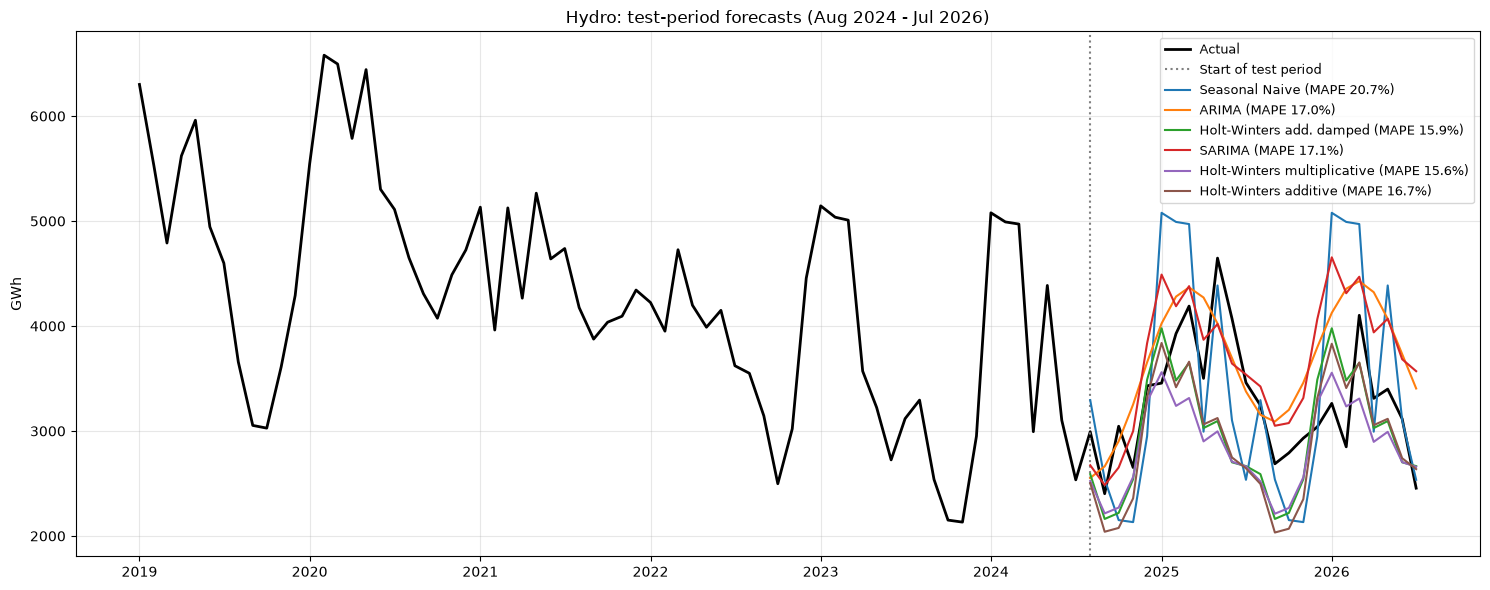

In [14]:
plot_forecasts("hydro", all_forecasts["hydro"], all_tables["hydro"])

**Hydro: model results**

* **Best model: ARIMA(3,0,2) with a constant.** MAPE 17.0%, MASE 0.486, a 22% lower MAE than the seasonal naive (MAPE 20.7%).
* The top four models are essentially **tied**: ARIMA (MASE 0.486), Holt-Winters additive damped (0.493), **SARIMA(1,0,0)(1,0,1)12** (0.494) and Holt-Winters multiplicative (0.495).
  All four do the same thing: they pull the forecast back toward the long-run average level and add the winter/autumn cycle.
* The tree model (Random Forest, MAPE 31.6%) and SARIMAX with Fourier terms (24.5%) do worst. Hydro has no trend or growth to learn, and its errors come from rainfall that no model can see in advance.
* Even the best hydro error (about 17%) is much larger than for biomass. This supports **H4**: hydro is hard to forecast because it is driven by the weather.

### 5.2 Residual analysis of the best hydro model
The residuals are one-step-ahead errors over the 60 months before the test period, re-estimating the model each month. A good model leaves residuals with **mean ≈ 0**, **no autocorrelation** (Ljung-Box p > 0.05) and roughly normal shape.

Best hydro model on the test period: ARIMA


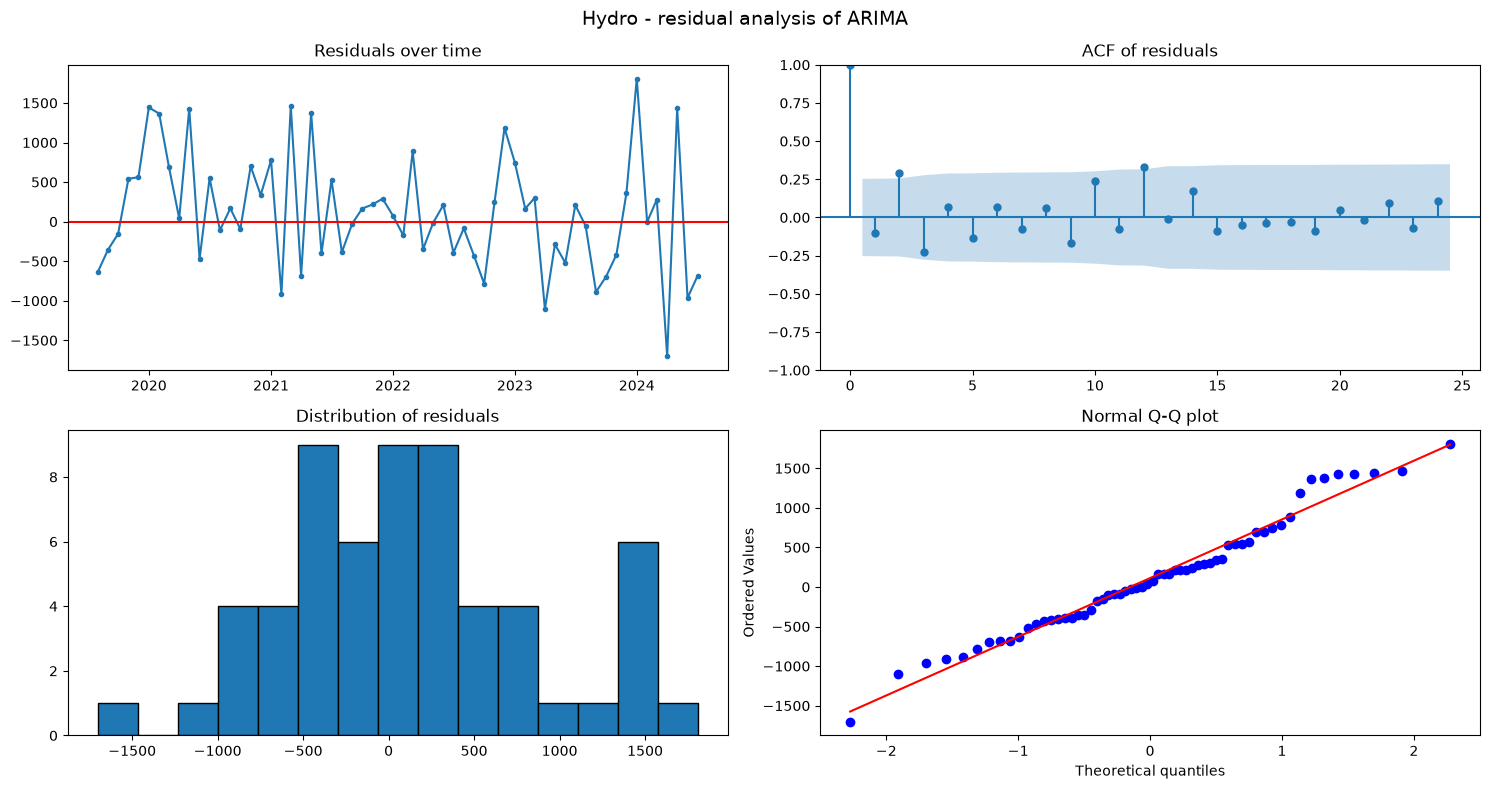

,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,hydro,ARIMA,60,112.267,0.240,732.970,0.075,0.007,0.341


In [15]:
best_hydro = all_tables["hydro"].index[0]
print("Best hydro model on the test period:", best_hydro)
one_step_hydro, test_err_hydro = residual_analysis("hydro", best_hydro)
residual_rows.append(residual_report("hydro", best_hydro, one_step_hydro))
pd.DataFrame([residual_rows[-1]])

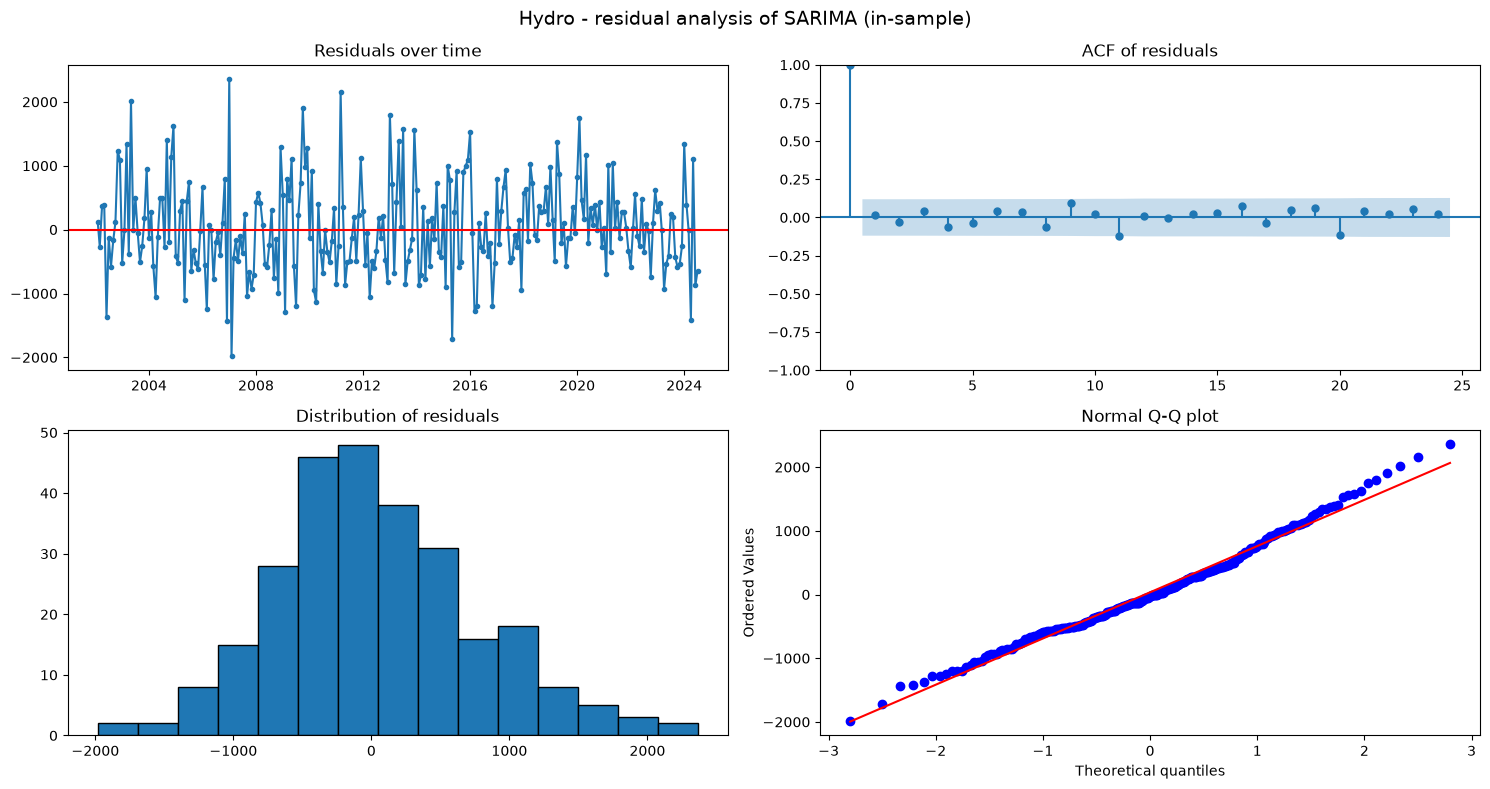

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       3763.2039    472.591      7.963      0.000    2836.942    4689.466
ar.L1          0.7468      0.040     18.644      0.000       0.668       0.825
ar.S.L12       0.9897      0.018     53.649      0.000       0.954       1.026
ma.S.L12      -0.9214      0.070    -13.180      0.000      -1.058      -0.784
sigma2      5.084e+05    4.4e+04     11.567      0.000    4.22e+05    5.95e+05


,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,hydro,SARIMA (in-sample),270,35.299,0.425,725.186,0.827,0.507,0.020


In [16]:
# For comparison: residuals of the SARIMA model fitted on the training data (in-sample, model scale)
o = orders["hydro"]["SARIMA"]
sarima_fit = ARIMA(to_model_scale(train["hydro"], "hydro"), order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
sarima_resid = sarima_fit.resid.iloc[13:]
residual_rows.append(residual_report("hydro", "SARIMA (in-sample)", sarima_resid))
print(sarima_fit.summary().tables[1])
pd.DataFrame([residual_rows[-1]])

**Hydro: residual interpretation**

* **ARIMA (best on test):** the mean one-step error (+112 GWh) is not significantly different from 0 (p = 0.24) and is roughly normal (Shapiro p = 0.34). However, Ljung-Box is **significant at lag 12 (p = 0.007)**. The non-seasonal ARIMA leaves the **yearly pattern** in its residuals.
* **SARIMA(1,0,0)(1,0,1)12:** residual mean ≈ 0 (p = 0.43) and **no autocorrelation** (Ljung-Box p = 0.83 at lag 6 and 0.51 at lag 12). These are white-noise residuals. They are slightly non-normal (Shapiro p = 0.02) because of extreme wet months.

ARIMA and SARIMA are tied on accuracy (MASE 0.486 vs 0.494), and only SARIMA leaves white-noise residuals. **SARIMA is therefore the more reliable hydro model.** ARIMA's small edge on the test set does not justify ignoring the seasonal structure it leaves behind.

## 6. Wind — separate models

### 6.1 Baseline, ARIMA/SARIMA/SARIMAX, Holt-Winters, ML and neural network (test period)

In [17]:
all_forecasts["wind"], all_tables["wind"] = run_all_models("wind")
all_tables["wind"]

,family,MAE,RMSE,MAPE,MASE
model,,,,,
Holt-Winters multiplicative,Holt-Winters,958.893,1182.227,6.983,1.046
Holt-Winters add. damped,Holt-Winters,1058.345,1362.808,7.887,1.154
Holt-Winters additive,Holt-Winters,1109.892,1424.868,8.430,1.210
Seasonal Naive,Baseline,1496.872,1884.699,10.004,1.632
Holt (damped),Exponential smoothing,2295.558,2827.552,15.461,2.503
SES,Exponential smoothing,2443.110,2962.139,16.352,2.664
Random Forest,ML,2746.806,3151.948,19.236,2.996
Naive,Baseline,2868.128,3356.238,18.828,3.128
SARIMA,SARIMA,2871.235,3285.744,20.036,3.131


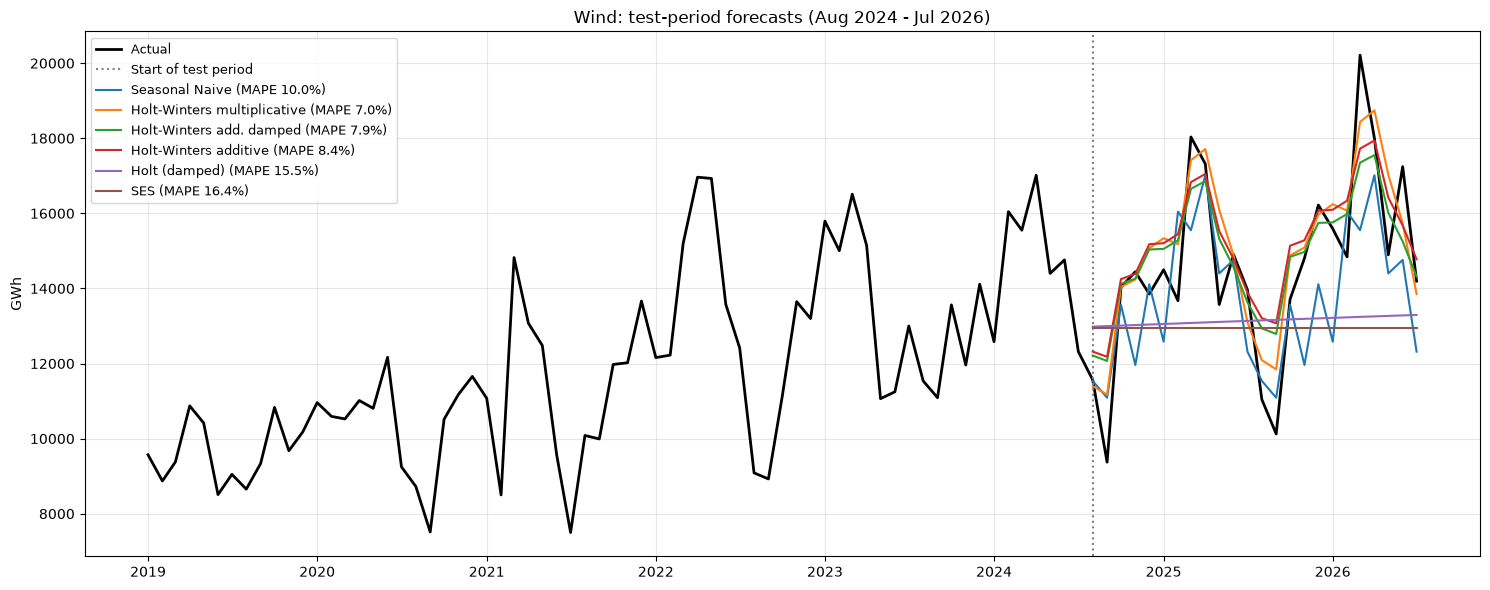

In [18]:
plot_forecasts("wind", all_forecasts["wind"], all_tables["wind"])

**Wind: model results**

* **Best model: Holt-Winters multiplicative.** MAPE **7.0%**, MASE 1.05, a **36% lower MAE** than the seasonal naive (10.0%). The other Holt-Winters variants come next (7.9% and 8.4%).
* Holt-Winters works well because it updates the **level** and **seasonal shape** gradually. That suits wind, whose growth has slowed to a few % per year while its spring-peak pattern stays very stable.
* **SARIMA performs poorly here (20.0%).** Its seasonal AR coefficient is almost exactly 1 (0.997), so it effectively carries forward a growth path from the years when wind grew 15–30% per year, and over-forecasts the recent slowdown.
* ML (Random Forest 19.2%, Linear Regression 30.1%) and the neural network (40.0%) do badly. With growth slowing, past growth rates are a poor guide, and these models extrapolate them.
* Naive and SES (16–19%) ignore seasonality. Their errors confirm that the spring/summer cycle must be modelled (**H2 supported for Holt-Winters**).

### 6.2 Residual analysis of the best wind model
The residuals are one-step-ahead errors over the 60 months before the test period, re-estimating the model each month. A good model leaves residuals with **mean ≈ 0**, **no autocorrelation** (Ljung-Box p > 0.05) and roughly normal shape.

Best wind model on the test period: Holt-Winters multiplicative


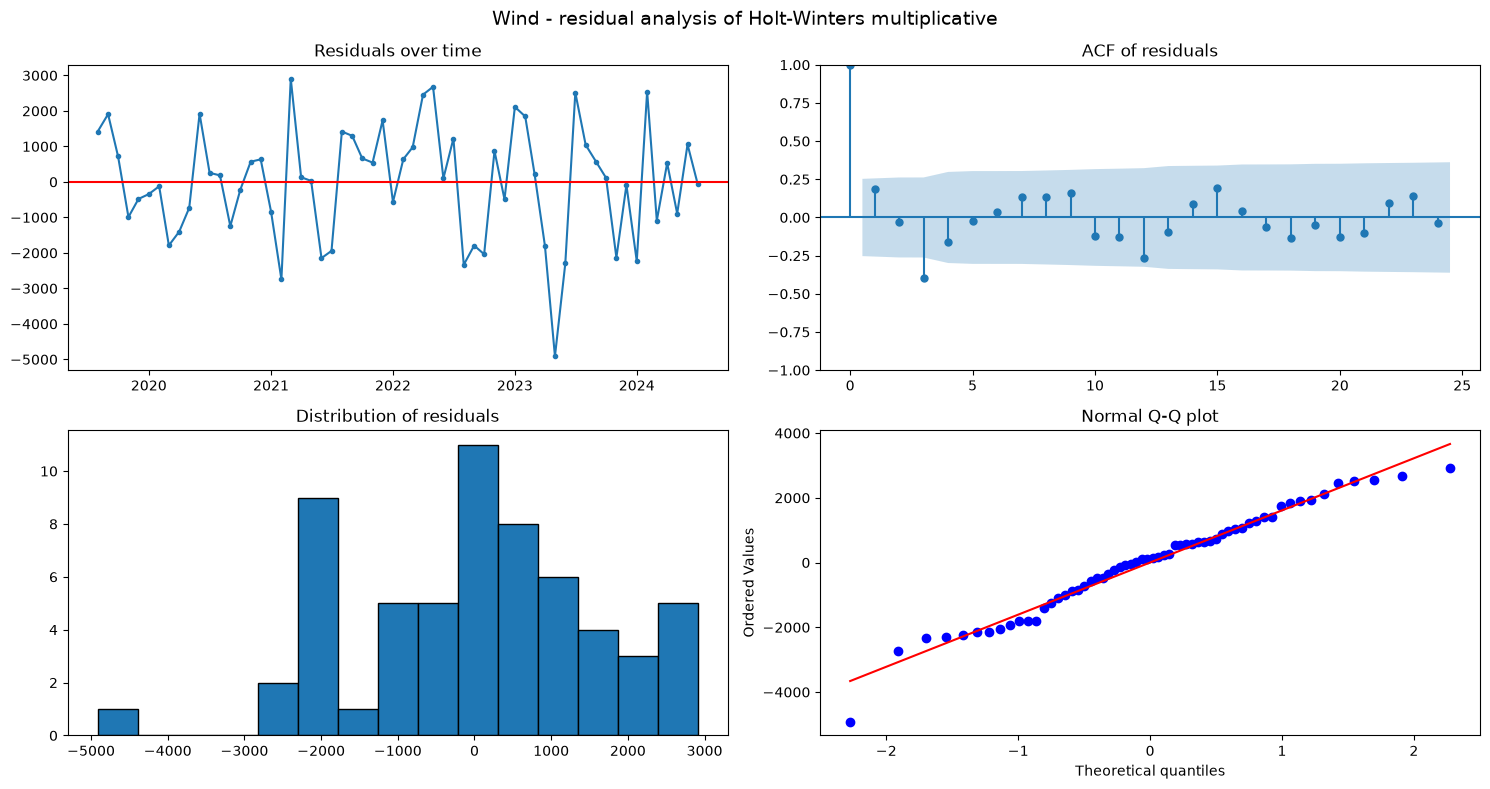

,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,wind,Holt-Winters multiplicative,60,1.785,0.993,1593.663,0.025,0.008,0.277


In [19]:
best_wind = all_tables["wind"].index[0]
print("Best wind model on the test period:", best_wind)
one_step_wind, test_err_wind = residual_analysis("wind", best_wind)
residual_rows.append(residual_report("wind", best_wind, one_step_wind))
pd.DataFrame([residual_rows[-1]])

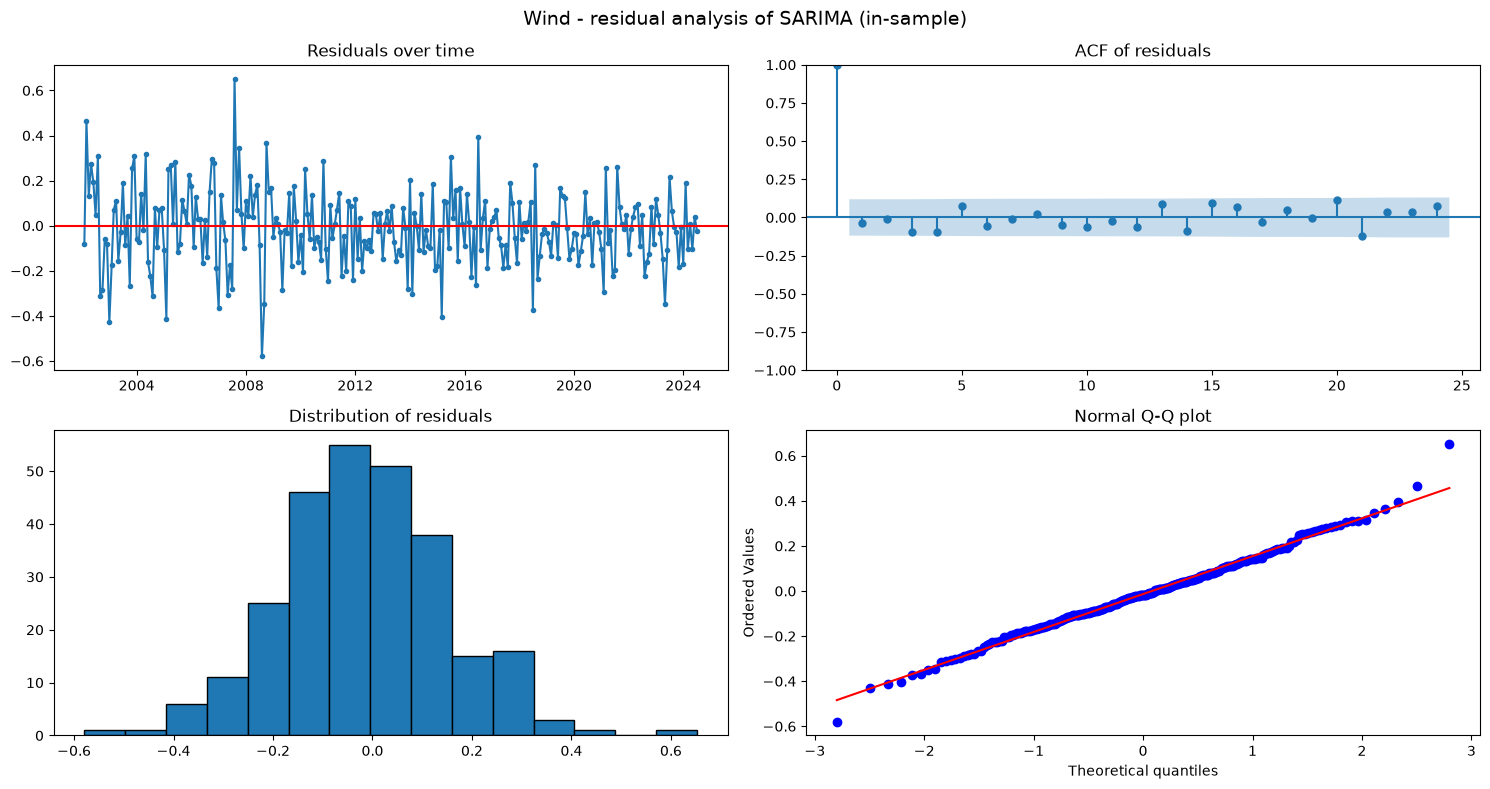

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1858      0.086      2.170      0.030       0.018       0.354
ma.L1         -0.7276      0.055    -13.112      0.000      -0.836      -0.619
ar.S.L12       0.9971      0.008    118.955      0.000       0.981       1.013
ma.S.L12      -0.9360      0.090    -10.360      0.000      -1.113      -0.759
sigma2         0.0297      0.003     10.634      0.000       0.024       0.035


,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,wind,SARIMA (in-sample),270,-0.013,0.188,0.168,0.255,0.536,0.224


In [20]:
# For comparison: residuals of the SARIMA model fitted on the training data (in-sample, model scale)
o = orders["wind"]["SARIMA"]
sarima_fit = ARIMA(to_model_scale(train["wind"], "wind"), order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
sarima_resid = sarima_fit.resid.iloc[13:]
residual_rows.append(residual_report("wind", "SARIMA (in-sample)", sarima_resid))
print(sarima_fit.summary().tables[1])
pd.DataFrame([residual_rows[-1]])

**Wind: residual interpretation**

* **Holt-Winters multiplicative (best on test):** the mean one-step error is essentially 0 (+1.8 GWh, p = 0.99) and the errors are normal (Shapiro p = 0.28), so the model is **unbiased**. However, there is some autocorrelation left (Ljung-Box p = 0.025 at lag 6, 0.008 at lag 12), so a small part of the month-to-month and yearly structure is not captured.
* **SARIMA(1,1,1)(1,0,1)12 on log(wind):** in-sample residuals are white noise (mean ≈ 0, p = 0.19; Ljung-Box p = 0.26 and 0.54; Shapiro p = 0.22). SARIMA describes the *past* well but forecasts the *recent slowdown* badly.

This illustrates an important point: **a model with perfect in-sample residuals is not guaranteed to forecast best when the trend changes**. Holt-Winters adapts to the slowdown faster.

## 7. Solar — separate models

### 7.1 Baseline, ARIMA/SARIMA/SARIMAX, Holt-Winters, ML and neural network (test period)

In [21]:
all_forecasts["solar"], all_tables["solar"] = run_all_models("solar")
all_tables["solar"]

,family,MAE,RMSE,MAPE,MASE
model,,,,,
Random Forest,ML,595.798,718.755,5.492,1.105
Neural Network (MLP),Neural network,1182.812,1783.945,9.374,2.194
Holt-Winters additive,Holt-Winters,1695.592,2152.780,12.686,3.145
Holt-Winters multiplicative,Holt-Winters,1736.161,1933.365,14.445,3.220
Holt-Winters add. damped,Holt-Winters,1747.140,2217.685,13.068,3.241
SARIMA,SARIMA,2190.415,2929.240,17.124,4.063
Holt (damped),Exponential smoothing,2964.476,3616.451,25.450,5.499
SES,Exponential smoothing,3002.226,3679.346,25.406,5.569
Naive,Baseline,3002.226,3679.346,25.406,5.569


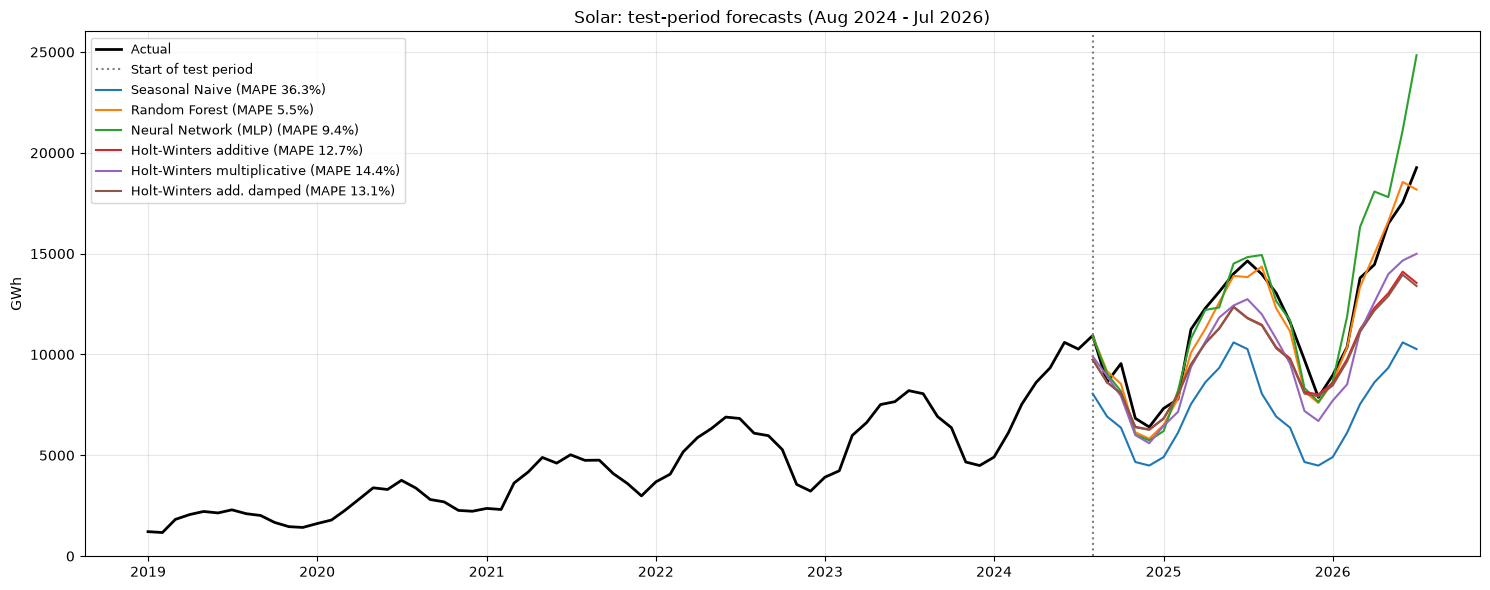

In [22]:
plot_forecasts("solar", all_forecasts["solar"], all_tables["solar"])

**Solar: model results**

* **Best model: Random Forest** on lag features of year-on-year log growth. MAPE **5.5%**, MASE 1.11, an 86% lower MAE than the seasonal naive.
* The seasonal naive is the **worst** model (MAPE 36.3%), and naive and SES are also poor (25.4%). They cannot follow growth of about 30–40% per year, which **supports H3**.
* The neural network (MLP) comes second (9.4%), then Holt-Winters (12.7–14.4%) and SARIMA (17.1%). SARIMA and Holt-Winters under-forecast the 2025–26 jump, when growth accelerated beyond its earlier trend.
* Linear regression on the same features fails (33.7%). Its linear growth extrapolation overshoots over 24 recursive steps.
* Note: the MASE values for solar are all above 1. MASE is scaled by in-sample seasonal-naive errors from years when solar was tiny, so for solar **MAPE is the meaningful comparison**.

### 7.2 Residual analysis of the best solar model
The residuals are one-step-ahead errors over the 60 months before the test period, re-estimating the model each month. A good model leaves residuals with **mean ≈ 0**, **no autocorrelation** (Ljung-Box p > 0.05) and roughly normal shape.

Best solar model on the test period: Random Forest


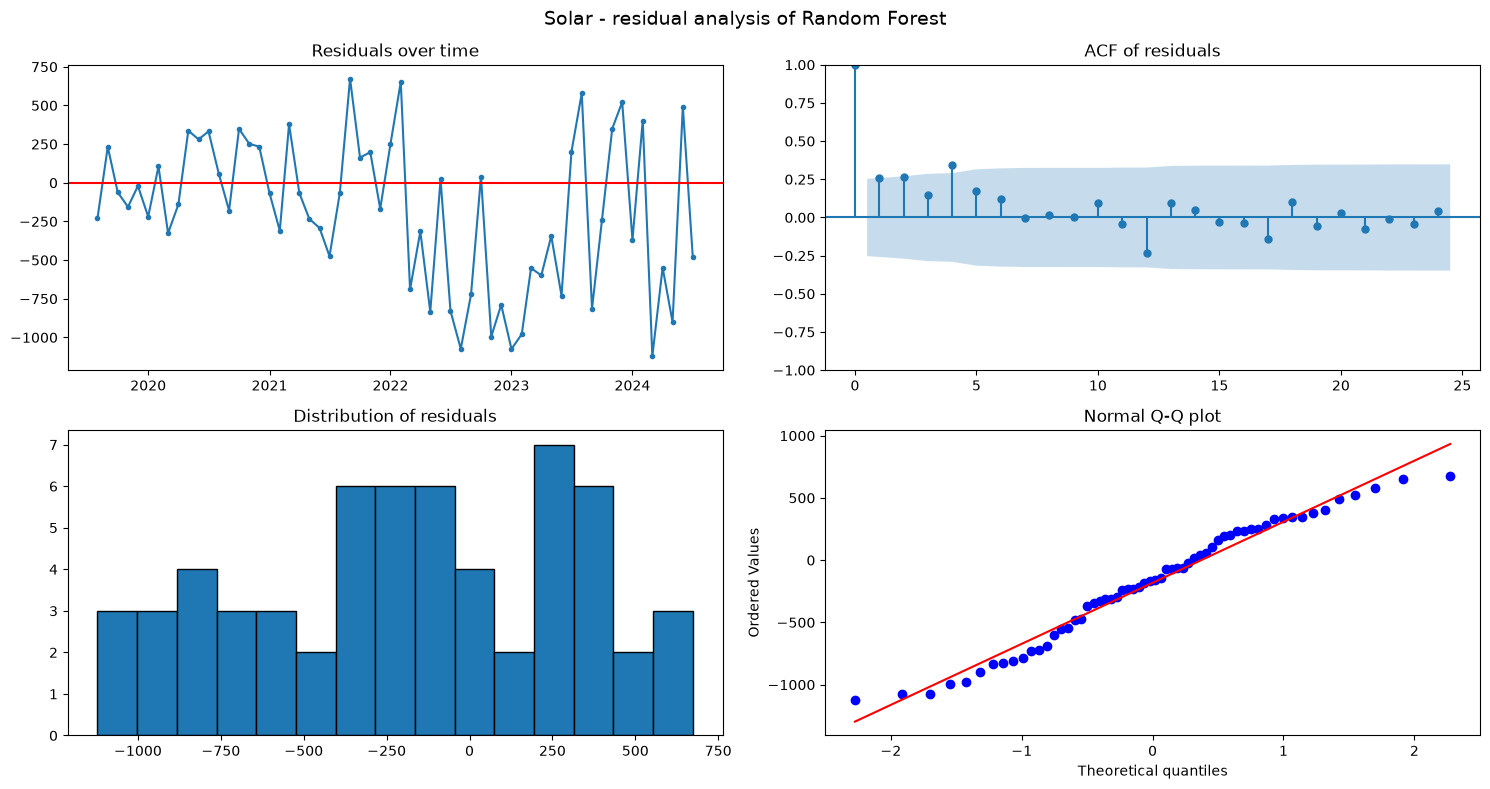

,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,solar,Random Forest,60,-181.784,0.005,484.966,0.002,0.010,0.105


In [23]:
best_solar = all_tables["solar"].index[0]
print("Best solar model on the test period:", best_solar)
one_step_solar, test_err_solar = residual_analysis("solar", best_solar)
residual_rows.append(residual_report("solar", best_solar, one_step_solar))
pd.DataFrame([residual_rows[-1]])

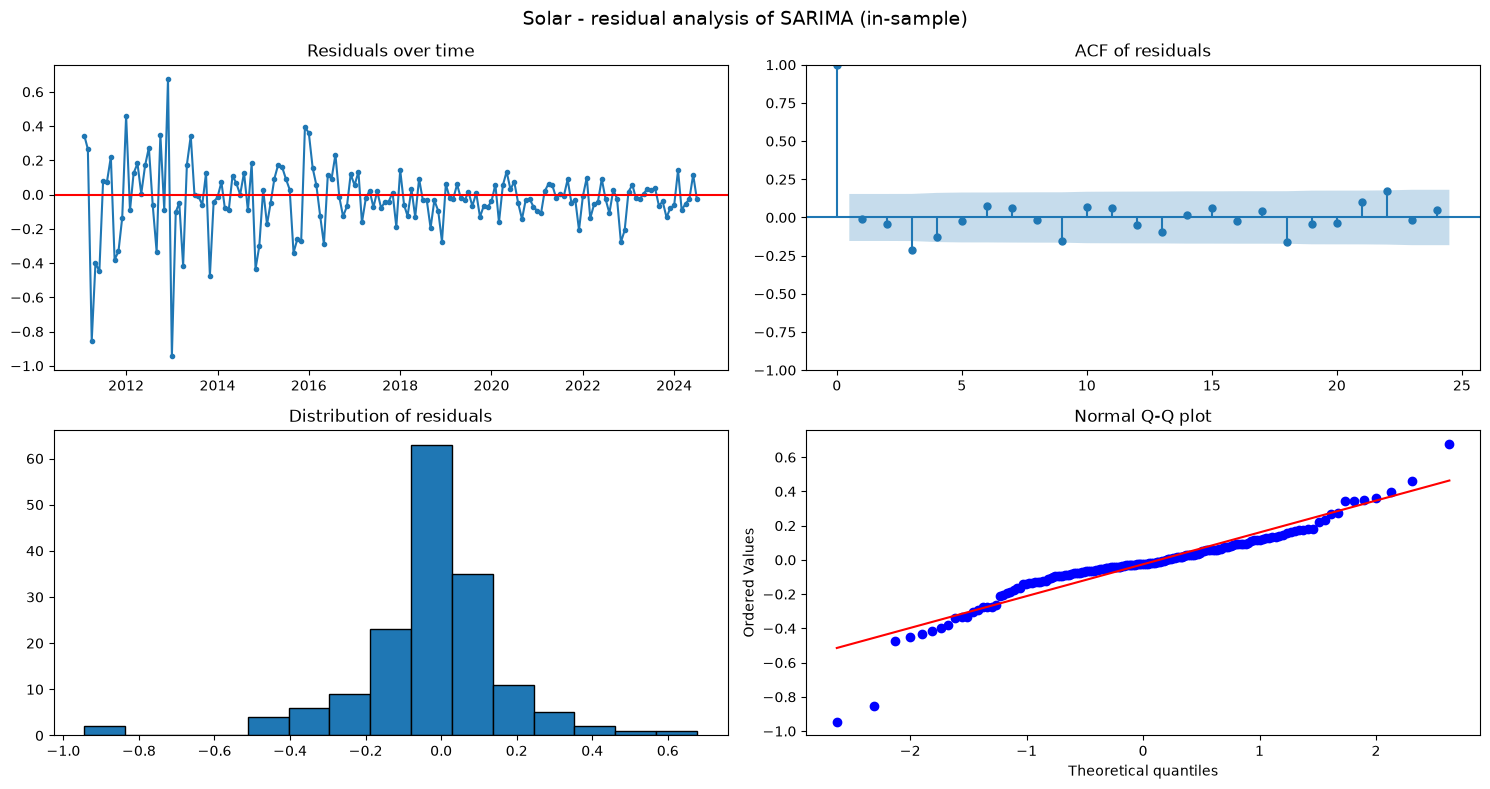

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4548      0.052     -8.698      0.000      -0.557      -0.352
ma.S.L12      -0.8548      0.125     -6.859      0.000      -1.099      -0.610
sigma2         0.0298      0.004      7.777      0.000       0.022       0.037


,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,solar,SARIMA (in-sample),162,-0.025,0.099,0.194,0.069,0.100,0.000


In [24]:
# For comparison: residuals of the SARIMA model fitted on the training data (in-sample, model scale)
o = orders["solar"]["SARIMA"]
sarima_fit = ARIMA(to_model_scale(train["solar"], "solar"), order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
sarima_resid = sarima_fit.resid.iloc[13:]
residual_rows.append(residual_report("solar", "SARIMA (in-sample)", sarima_resid))
print(sarima_fit.summary().tables[1])
pd.DataFrame([residual_rows[-1]])

**Solar: residual interpretation**

* **Random Forest:** the mean one-step error is −182 GWh and **significantly negative** (p = 0.005). The model tends to **over-forecast** month by month. The residuals are also **autocorrelated** (Ljung-Box p = 0.002 at lag 6). It wins on the 24-month test, but its errors are not white noise. Its 24-month advantage partly reflects how well its growth-rate approach matched the 2025–26 surge.
* **SARIMA(1,1,0)(0,1,1)12 on log(solar):** residual mean ≈ 0 (p = 0.10) and Ljung-Box p = 0.07 (lag 6) and 0.10 (lag 12). These are **white-noise residuals**, so the model captures all of the linear time structure. The residuals are non-normal (Shapiro p < 0.001) because of a few unusual months.

**Conclusion for solar:** Random Forest gives the most accurate forecasts, and SARIMA gives the statistically cleanest description of the series.

## 8. Biomass — separate models

### 8.1 Baseline, ARIMA/SARIMA/SARIMAX, Holt-Winters, ML and neural network (test period)

In [25]:
all_forecasts["biomass"], all_tables["biomass"] = run_all_models("biomass")
all_tables["biomass"]

,family,MAE,RMSE,MAPE,MASE
model,,,,,
SARIMA,SARIMA,77.442,88.995,4.035,0.694
Seasonal Naive,Baseline,147.784,169.555,7.730,1.325
SARIMAX (Fourier exog),SARIMAX,148.785,167.063,7.849,1.334
Holt-Winters add. damped,Holt-Winters,151.113,165.429,7.883,1.355
Holt-Winters additive,Holt-Winters,155.820,170.571,8.128,1.397
ARIMA,ARIMA,157.682,176.100,8.318,1.414
Holt-Winters multiplicative,Holt-Winters,162.178,177.048,8.486,1.454
Holt (damped),Exponential smoothing,176.556,210.565,9.443,1.583
SES,Exponential smoothing,179.056,213.008,9.574,1.606


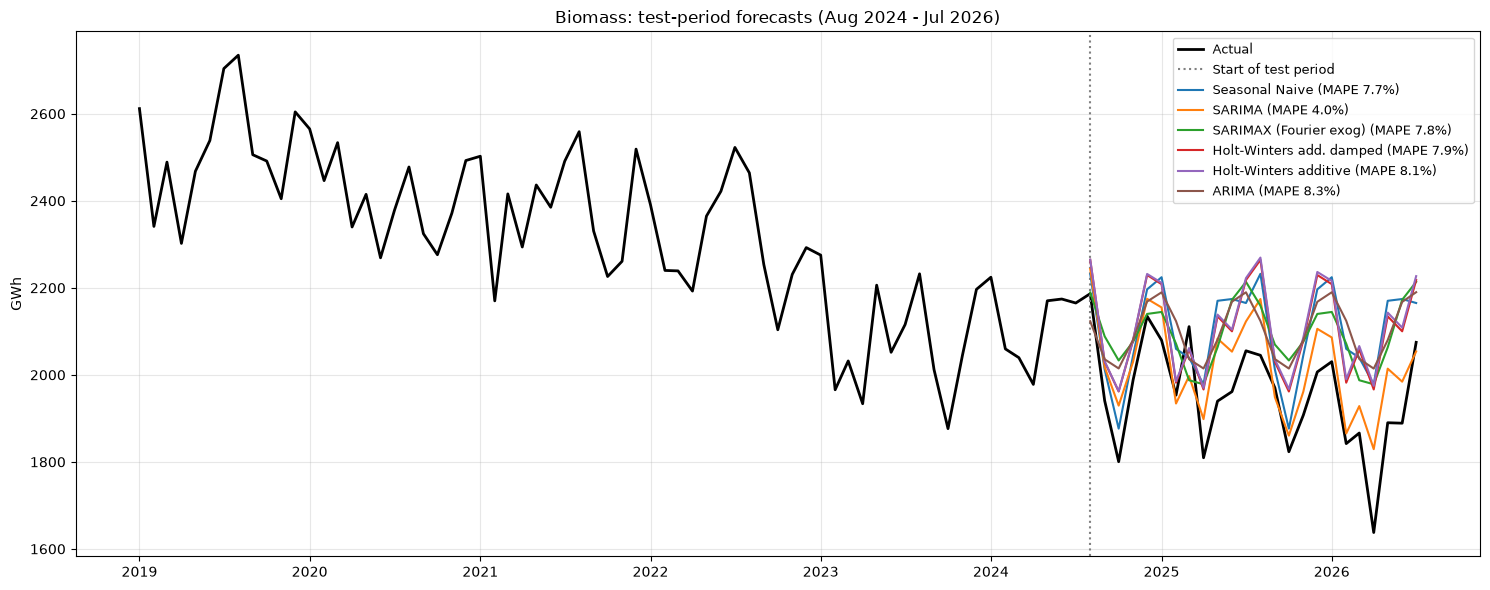

In [26]:
plot_forecasts("biomass", all_forecasts["biomass"], all_tables["biomass"])

**Biomass: model results**

* **Best model: SARIMA(0,1,1)(0,1,1)12** (the "airline" model). MAPE **4.0%**, MASE 0.694, a **48% lower MAE** than the seasonal naive (7.7%).
* SARIMA is the only model that is clearly better than the seasonal naive. SARIMAX, Holt-Winters and ARIMA all land at 7.8–8.5%, about the same as the baseline.
* The ML models (9.7–11.1%) and the neural network (10.5%) are **worse than the baseline**. With a small, regular seasonal ripple and a slowly drifting level, there is little non-linear structure for them to learn.
* Biomass is the **easiest** resource to forecast. This supports **H2** for SARIMA (though not for Holt-Winters).

### 8.2 Residual analysis of the best biomass model
The residuals are one-step-ahead errors over the 60 months before the test period, re-estimating the model each month. A good model leaves residuals with **mean ≈ 0**, **no autocorrelation** (Ljung-Box p > 0.05) and roughly normal shape.

Best biomass model on the test period: SARIMA


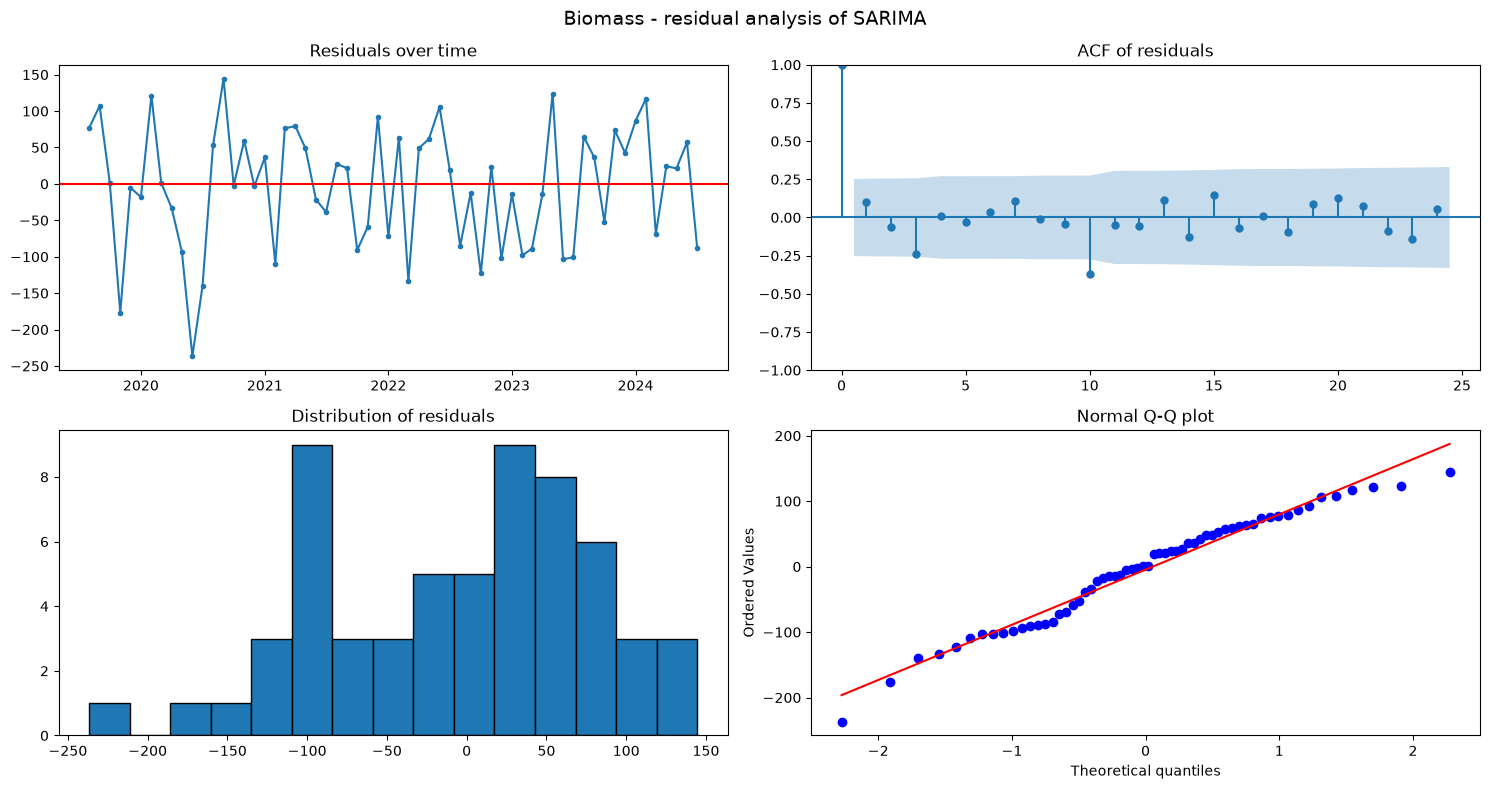

,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,biomass,SARIMA,60,-4.463,0.681,83.557,0.571,0.171,0.164


In [27]:
best_biomass = all_tables["biomass"].index[0]
print("Best biomass model on the test period:", best_biomass)
one_step_biomass, test_err_biomass = residual_analysis("biomass", best_biomass)
residual_rows.append(residual_report("biomass", best_biomass, one_step_biomass))
pd.DataFrame([residual_rows[-1]])

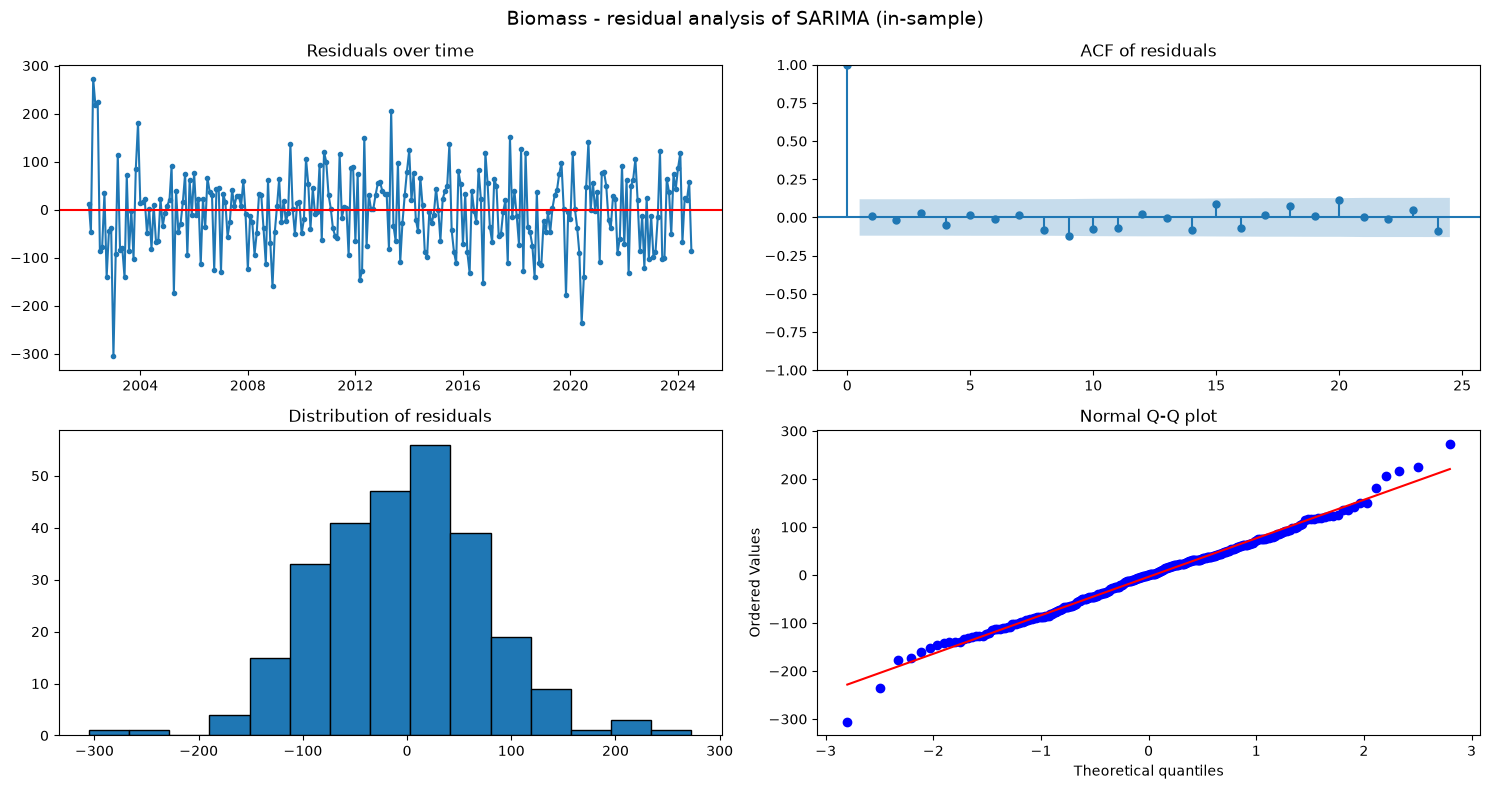

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4380      0.048     -9.081      0.000      -0.533      -0.343
ma.S.L12      -0.7033      0.051    -13.793      0.000      -0.803      -0.603
sigma2      5954.7357    515.034     11.562      0.000    4945.288    6964.183


,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,biomass,SARIMA (in-sample),270,-3.766,0.440,80.091,0.977,0.570,0.137


In [28]:
# For comparison: residuals of the SARIMA model fitted on the training data (in-sample, model scale)
o = orders["biomass"]["SARIMA"]
sarima_fit = ARIMA(to_model_scale(train["biomass"], "biomass"), order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
sarima_resid = sarima_fit.resid.iloc[13:]
residual_rows.append(residual_report("biomass", "SARIMA (in-sample)", sarima_resid))
print(sarima_fit.summary().tables[1])
pd.DataFrame([residual_rows[-1]])

**Biomass: residual interpretation**

The SARIMA residuals are **white noise** by every test, both for the one-step forecast errors and in-sample:
* mean ≈ 0 (p = 0.68 and 0.44);
* no autocorrelation (Ljung-Box p = 0.57 / 0.17 and 0.98 / 0.57);
* normally distributed (Shapiro p = 0.16 and 0.14).

The model has captured all the trend, seasonal and short-term dependence in biomass generation. Its estimated coefficients (MA(1) = −0.44, seasonal MA(1) = −0.70) are highly significant.

## 9. Model comparison across resources

In [29]:
summary_rows = []
for r in RESOURCES:
    t = all_tables[r]
    for family in ["Baseline", "ARIMA", "SARIMA", "SARIMAX", "Exponential smoothing", "Holt-Winters", "ML", "Neural network"]:
        best_in_family = t[t.family == family].sort_values("MASE").iloc[0]
        summary_rows.append({"resource": r, "family": family, "model": best_in_family.name,
                             "MAPE": best_in_family.MAPE, "MASE": best_in_family.MASE})
summary = pd.DataFrame(summary_rows)

print("MAPE (%) of the best model in each family:")
mape_table = summary.pivot(index="resource", columns="family", values="MAPE")
mape_table["Best model"] = [all_tables[r].index[0] for r in mape_table.index]
display(mape_table)

print("MASE of the best model in each family (lower is better, < 1 beats seasonal naive in-sample):")
display(summary.pivot(index="resource", columns="family", values="MASE"))

MAPE (%) of the best model in each family:


family,ARIMA,Baseline,Exponential smoothing,Holt-Winters,ML,Neural network,SARIMA,SARIMAX,Best model
resource,,,,,,,,,
biomass,8.318,7.730,9.443,7.883,9.731,10.452,4.035,7.849,SARIMA
hydro,16.979,20.690,20.520,15.928,20.348,20.698,17.129,24.468,ARIMA
solar,29.699,25.406,25.450,12.686,5.492,9.374,17.124,33.479,Random Forest
wind,27.980,10.004,15.461,6.983,19.236,40.010,20.036,26.882,Holt-Winters multiplicative


MASE of the best model in each family (lower is better, < 1 beats seasonal naive in-sample):


family,ARIMA,Baseline,Exponential smoothing,Holt-Winters,ML,Neural network,SARIMA,SARIMAX
resource,,,,,,,,
biomass,1.414,1.325,1.583,1.355,1.677,1.801,0.694,1.334
hydro,0.486,0.625,0.675,0.493,0.624,0.625,0.494,0.701
solar,6.889,5.569,5.499,3.145,1.105,2.194,4.063,7.812
wind,4.098,1.632,2.503,1.046,2.996,6.127,3.131,4.246


In [30]:
best_overall = pd.DataFrame({
    r: {"best model": all_tables[r].index[0],
        "best MAPE %": all_tables[r].MAPE.iloc[0],
        "best MASE": all_tables[r].MASE.iloc[0],
        "Seasonal Naive MAPE %": all_tables[r].loc["Seasonal Naive", "MAPE"],
        "improvement over Seasonal Naive (MAE) %": (1 - all_tables[r].MAE.iloc[0] / all_tables[r].loc["Seasonal Naive", "MAE"]) * 100}
    for r in RESOURCES}).T
best_overall

,best model,best MAPE %,best MASE,Seasonal Naive MAPE %,improvement over Seasonal Naive (MAE) %
hydro,ARIMA,16.979,0.486,20.690,22.322
wind,Holt-Winters multiplicative,6.983,1.046,10.004,35.940
solar,Random Forest,5.492,1.105,36.342,86.261
biomass,SARIMA,4.035,0.694,7.730,47.598


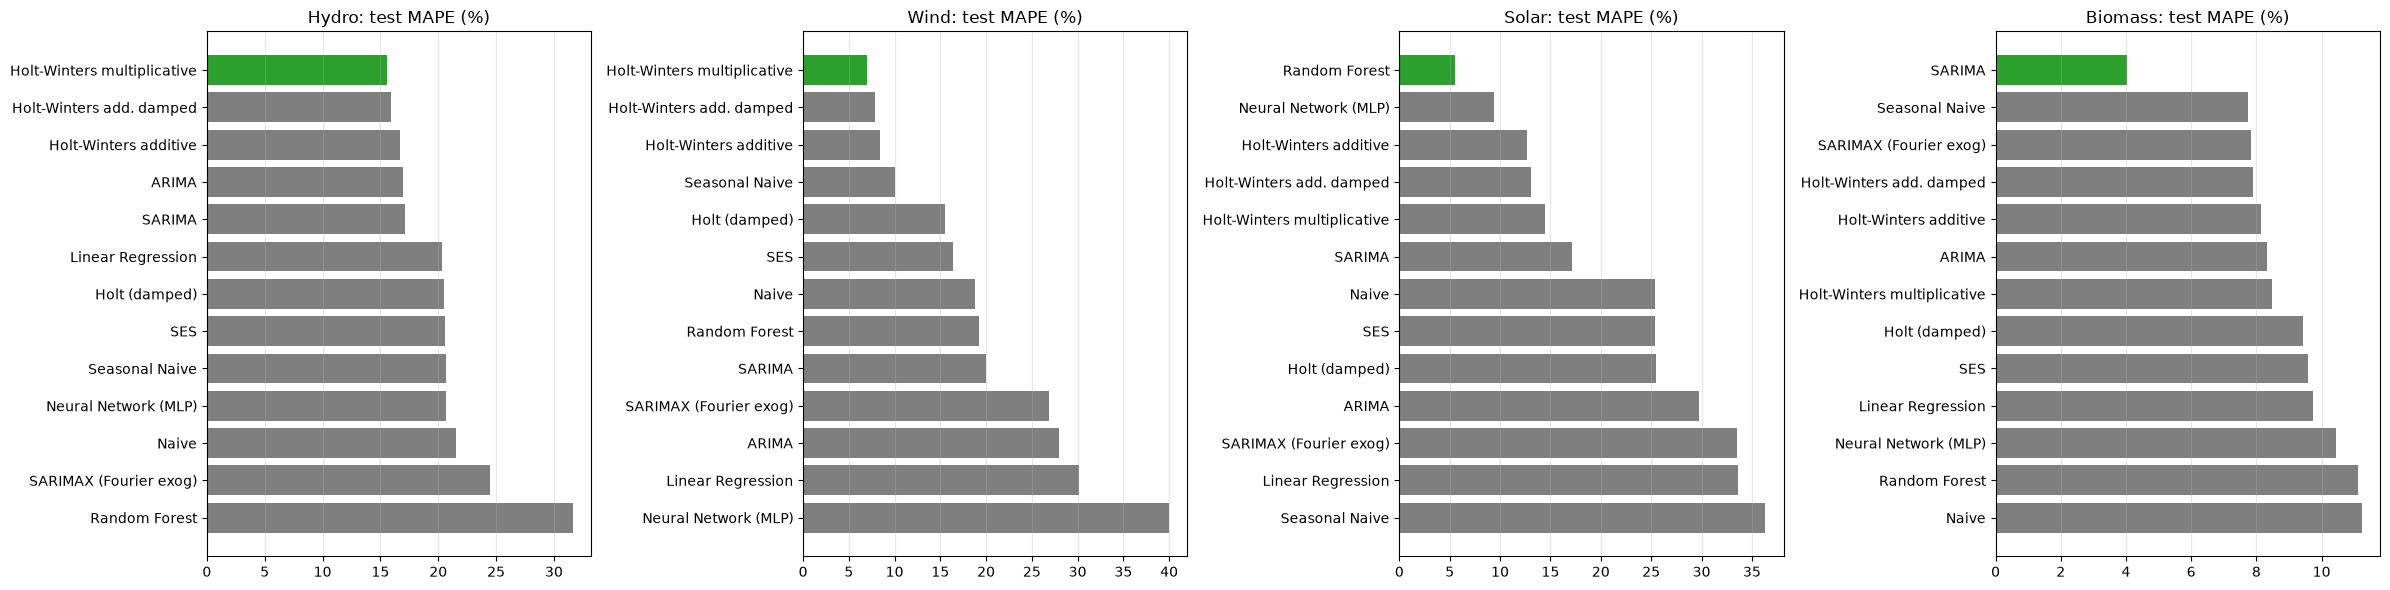

In [31]:
fig, axes = plt.subplots(1, 4, figsize=(24, 6))
for ax, r in zip(axes, RESOURCES):
    t = all_tables[r].sort_values("MAPE")
    ax.barh(t.index, t.MAPE, color=["tab:green" if i == 0 else "tab:gray" for i in range(len(t))])
    ax.invert_yaxis()
    ax.set_title(f"{r.capitalize()}: test MAPE (%)")
    ax.grid(True, alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

**Model comparison across resources**

| Resource | Best model | MAPE | Seasonal naive MAPE | Improvement in MAE |
|---|---|---|---|---|
| Biomass | SARIMA(0,1,1)(0,1,1)12 | **4.0%** | 7.7% | 48% |
| Solar | Random Forest (growth-rate target) | 5.5% | 36.3% | 86% |
| Wind | Holt-Winters multiplicative | 7.0% | 10.0% | 36% |
| Hydro | ARIMA(3,0,2) (SARIMA tied, with better residuals) | 17.0% | 20.7% | 22% |

* **A different model wins for each resource.** This confirms that each resource must be modelled separately.
* **Difficulty ranking:** biomass (easiest) → solar → wind → hydro (hardest). This **supports H4**.
* **H2 (seasonal models beat the baseline):**
  * supported for hydro, wind (Holt-Winters) and solar (Holt-Winters 12.7% vs 36.3%);
  * for biomass, only SARIMA beats the baseline.
* **H3 (growing resources need growth-aware models):**
  * supported for solar: trend-free models score 25–36%;
  * for wind, the right model is one that adapts to *slowing* growth (Holt-Winters). Models that extrapolate past high growth (SARIMA, ML) over-forecast.
* **Every best model beats the seasonal naive**, by 22–86% in MAE.

## 10. Forecast of the next 12 months (Aug 2026 – Jul 2027)
The best model of each resource is re-fitted on **all** data up to Jul 2026 and forecasts the next 12 months. The band is an approximate 90% range taken from that model's test-period percentage errors.

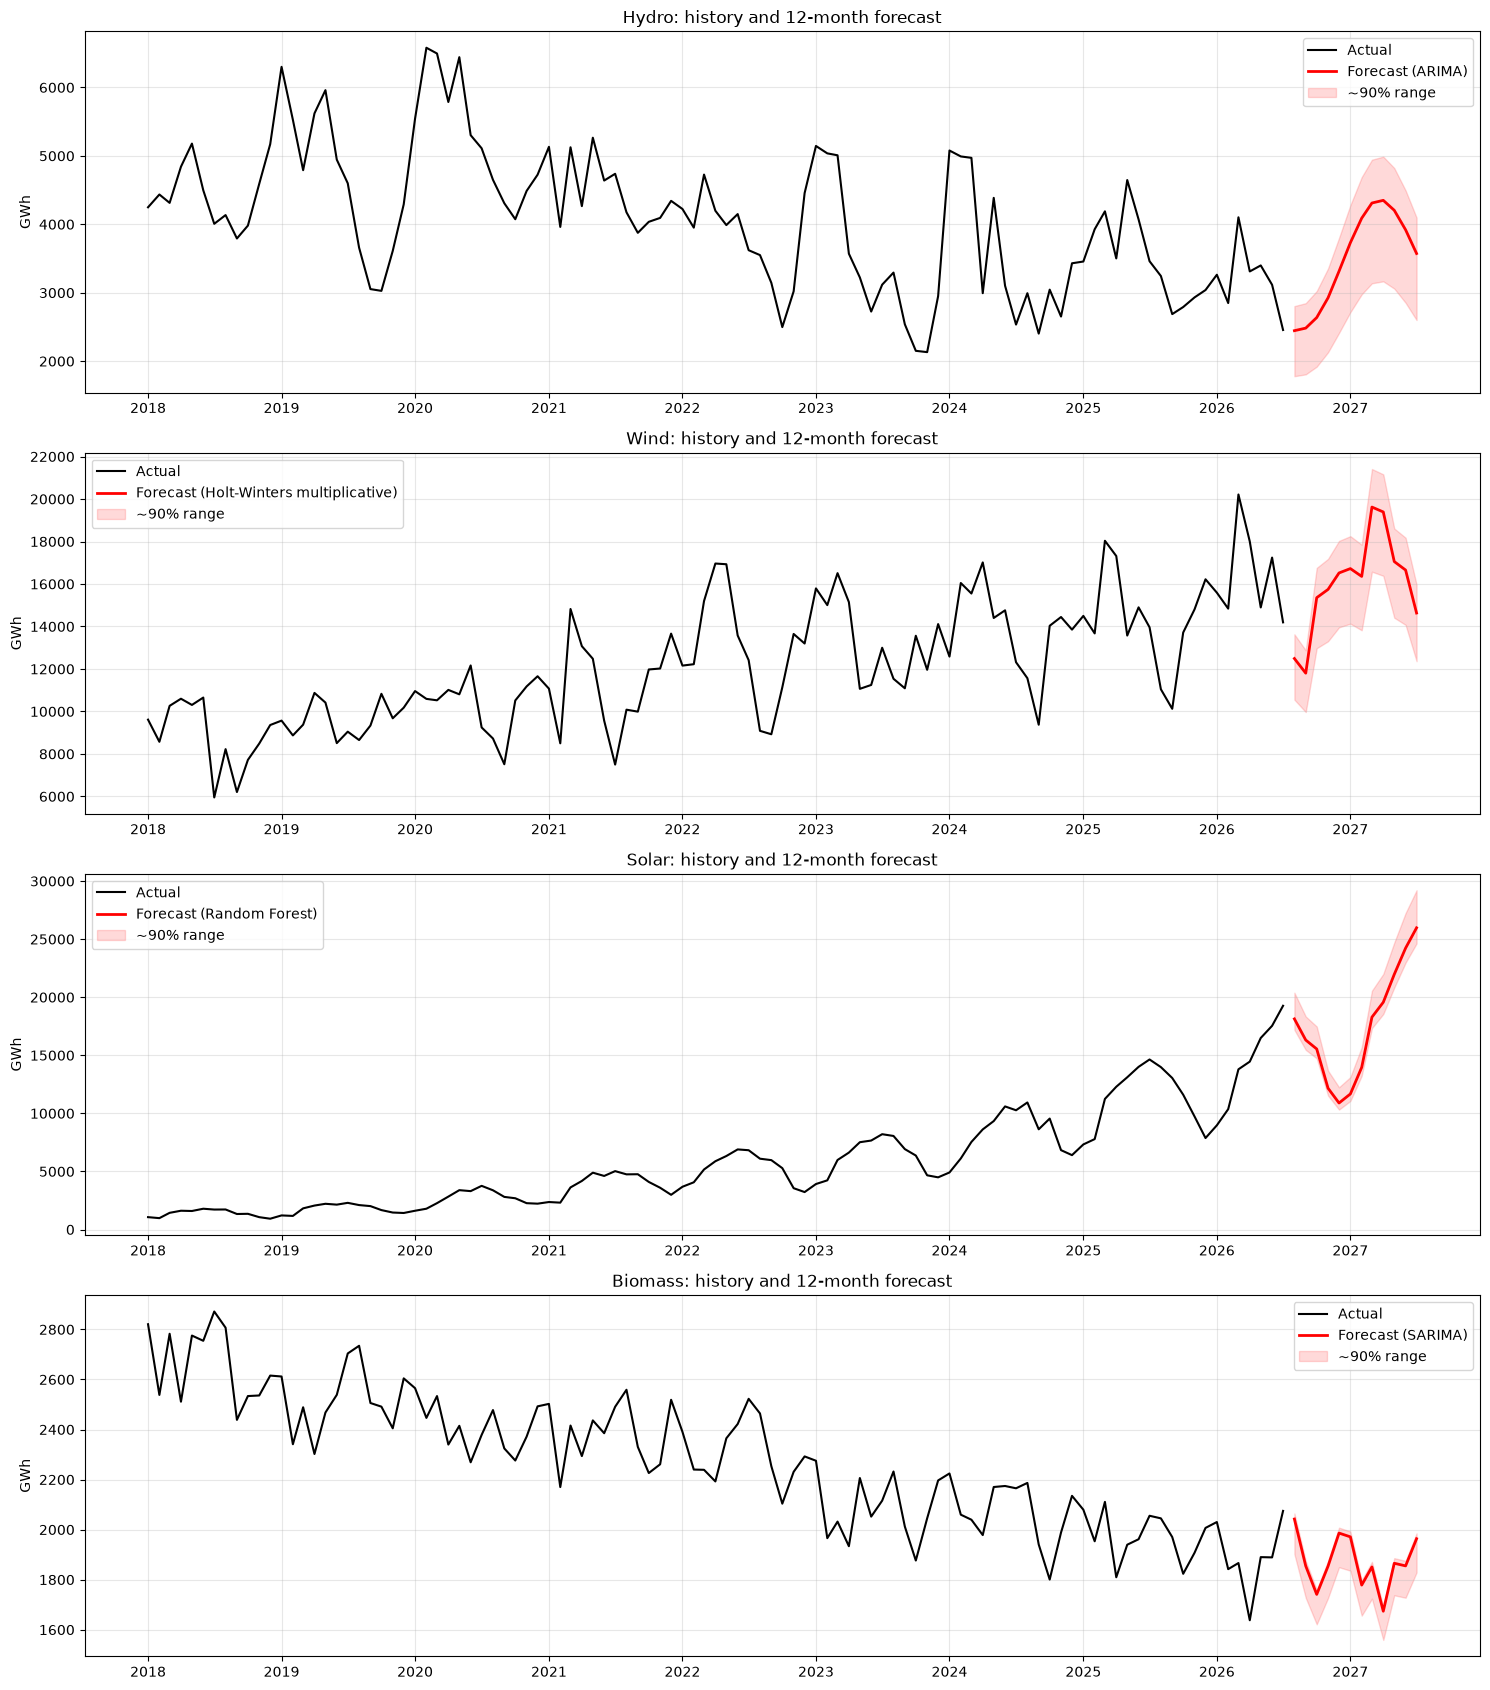

,best model,last 12 months (GWh),next 12 months forecast (GWh),change %,peak month,lowest month,"share of modelled renewables, next 12 m (%)"
hydro,ARIMA,37190.596,41985.347,12.892,Apr 2027,Aug 2026,9.020
wind,Holt-Winters multiplicative,180893.248,192352.214,6.335,Mar 2027,Sep 2026,41.324
solar,Random Forest,157117.392,208705.170,32.834,Jul 2027,Dec 2026,44.837
biomass,SARIMA,22982.679,22435.636,-2.380,Aug 2026,Apr 2027,4.820


In [32]:
future = {}
for r in RESOURCES:
    best = all_tables[r].index[0]
    fc = MODELS[best][1](series[r], H_FUTURE, r)
    idx = pd.date_range(series[r].index[-1] + pd.offsets.MonthBegin(), periods=H_FUTURE, freq="MS")
    pct_err = (test[r] - all_forecasts[r][best]) / all_forecasts[r][best]
    lo, hi = np.quantile(pct_err, [0.05, 0.95])
    future[r] = pd.DataFrame({"forecast": fc, "lower_90": fc * (1 + lo), "upper_90": fc * (1 + hi)}, index=idx)

fig, axes = plt.subplots(4, 1, figsize=(15, 17))
for ax, r in zip(axes, RESOURCES):
    ax.plot(series[r].loc["2018-01-01":], color="black", label="Actual")
    ax.plot(future[r].forecast, color="red", linewidth=2, label=f"Forecast ({all_tables[r].index[0]})")
    ax.fill_between(future[r].index, future[r].lower_90, future[r].upper_90, color="red", alpha=0.15, label="~90% range")
    ax.set_title(f"{r.capitalize()}: history and 12-month forecast")
    ax.set_ylabel("GWh")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

outlook = pd.DataFrame({
    r: {"best model": all_tables[r].index[0],
        "last 12 months (GWh)": series[r].iloc[-12:].sum(),
        "next 12 months forecast (GWh)": future[r].forecast.sum(),
        "change %": (future[r].forecast.sum() / series[r].iloc[-12:].sum() - 1) * 100,
        "peak month": future[r].forecast.idxmax().strftime("%b %Y"),
        "lowest month": future[r].forecast.idxmin().strftime("%b %Y")}
    for r in RESOURCES}).T
outlook["share of modelled renewables, next 12 m (%)"] = (
    outlook["next 12 months forecast (GWh)"].astype(float) / outlook["next 12 months forecast (GWh)"].astype(float).sum() * 100)
outlook

In [33]:
print("Monthly forecasts (GWh):")
pd.DataFrame({r: future[r].forecast for r in RESOURCES}).round(1)

Monthly forecasts (GWh):


,hydro,wind,solar,biomass
2026-08-01,2445.600,12491.200,18133.600,2042.200
2026-09-01,2482.900,11801.900,16313.700,1854.600
2026-10-01,2637.200,15355.500,15544.900,1741.000
2026-11-01,2925.700,15745.000,12162.300,1853.900
2026-12-01,3314.200,16519.700,10891.200,1986.100
2027-01-01,3731.200,16725.000,11671.800,1971.000
2027-02-01,4089.500,16356.500,13960.400,1778.200
2027-03-01,4311.200,19621.000,18286.100,1850.900
2027-04-01,4350.200,19390.700,19567.000,1673.800
2027-05-01,4204.900,17056.100,21966.900,1865.500


**Forecast for Aug 2026 – Jul 2027**

| Resource | Best model | Last 12 months | Forecast next 12 months | Change | Peak | Low |
|---|---|---|---|---|---|---|
| Solar | Random Forest | 157,117 GWh | **208,705 GWh** | **+32.8%** | Jul 2027 | Dec 2026 |
| Wind | HW multiplicative | 180,893 GWh | 192,352 GWh | +6.3% | Mar 2027 | Sep 2026 |
| Hydro | ARIMA | 37,191 GWh | 41,985 GWh | +12.9% | Apr 2027 | Aug 2026 |
| Biomass | SARIMA | 22,983 GWh | 22,436 GWh | −2.4% | Aug 2026 | Apr 2027 |

* **Solar is forecast to overtake wind** as the South's largest renewable source in the next 12 months: about 44.8% of the modelled renewable output vs about 41.3% for wind.
* **Wind** keeps growing, but slowly (+6.3%).
* **Hydro** recovers toward its long-run average (about 45,000 GWh/yr) after a below-average year. This is a mean-reversion forecast that depends on rainfall.
* **Biomass** continues its slow decline.
* Seasonally:
  * wind peaks in March;
  * solar peaks in July;
  * hydro peaks in April;
  * Sep–Dec is the weakest period for wind and solar combined.

## 11. Geothermal

Geothermal generation is **0 GWh in every month from Jan 2001 to Jul 2026** in all 17 Southern jurisdictions (Review 1, section 2).
There are no utility-scale geothermal plants in the region, so there is no time-series behaviour to model. Every model would forecast
exactly 0. The forecast for geothermal is therefore **0 GWh**, unless a new plant is built, which cannot be predicted from this data.

In [34]:
print("Geothermal generation in the South: min =", region["geothermal"].min(), "| max =", region["geothermal"].max(),
      "| months > 0 =", int((region["geothermal"] > 0).sum()))

Geothermal generation in the South: min = 0.0 | max = 0.0 | months > 0 = 0


## 12. Residual analysis summary

In [35]:
pd.DataFrame(residual_rows).set_index(["resource", "model"])

n     mean  mean t-test p      std  \
resource model                                                               
hydro    ARIMA                         60  112.267          0.240  732.970   
         SARIMA (in-sample)           270   35.299          0.425  725.186   
wind     Holt-Winters multiplicative   60    1.785          0.993 1593.663   
         SARIMA (in-sample)           270   -0.013          0.188    0.168   
solar    Random Forest                 60 -181.784          0.005  484.966   
         SARIMA (in-sample)           162   -0.025          0.099    0.194   
biomass  SARIMA                        60   -4.463          0.681   83.557   
         SARIMA (in-sample)           270   -3.766          0.440   80.091   

                                      Ljung-Box p (lag 6)  \
resource model                                              
hydro    ARIMA                                      0.075   
         SARIMA (in-sample)                         0.827   
wind     Holt-Winters multiplicative                0.025   
         SARIMA (in-sample)                         0.255   
solar    Random Forest                              0.002   
         SARIMA (in-sample)                         0.069   
biomass  SARIMA                                     0.571   
         SARIMA (in-sample)                         0.977   

                                      Ljung-Box p (lag 12)  Shapiro-Wilk p  
resource model                                                              
hydro    ARIMA                                       0.007           0.341  
         SARIMA (in-sample)                          0.507           0.020  
wind     Holt-Winters multiplicative                 0.008           0.277  
         SARIMA (in-sample)                          0.536           0.224  
solar    Random Forest                               0.010           0.105  
         SARIMA (in-sample)                          0.100           0.000  
biomass  SARIMA                                      0.171           0.164  
         SARIMA (in-sample)                          0.570           0.137

**Residual analysis summary**

* **SARIMA leaves white-noise residuals for all four resources** (Ljung-Box p > 0.05 at lags 6 and 12, mean ≈ 0), so it captures the time structure of every series.
* The best test models for **hydro** (ARIMA), **wind** (Holt-Winters) and **solar** (Random Forest) still leave some autocorrelation. Only **biomass** (SARIMA) has both the best accuracy and white-noise residuals.
* Lower test error and cleaner residuals do not always come from the same model. For hydro, SARIMA is tied on accuracy and is the more reliable choice. For wind, Holt-Winters is clearly more accurate despite slight autocorrelation.
* Normality is rejected only for some SARIMA residuals (hydro, solar), because of a few extreme months. This affects prediction intervals, not point forecasts.

## 13. Research Conclusion

**Answer to the research question**

Hydro, wind, solar, biomass and geothermal behave very differently over time in the Southern U.S. region:

* **Trend:**
  * hydro has no trend (stationary in levels);
  * wind has strong growth that is now slowing (about 23%/yr long-run, only 3–4%/yr since 2023);
  * solar has exponential growth (about 62%/yr);
  * biomass rose until 2017 and has declined since;
  * geothermal is absent.
* **Seasonality:** every active resource has a 12-month cycle, but each peaks at a different time:
  * hydro in winter (January +25%);
  * wind in spring (April +23%);
  * solar in late spring and summer (May +24%);
  * biomass is nearly flat (±6%).
  The cycles complement each other across the year.
* **Temporal dependence:** each has its own SARIMA structure, identified from the ACF/PACF and confirmed by AIC.

  | Resource | Structure |
  |---|---|
  | Hydro | (1,0,0)(1,0,1)12 |
  | Wind | (1,1,1)(1,0,1)12 on log |
  | Solar | (1,1,0)(0,1,1)12 on log |
  | Biomass | (0,1,1)(0,1,1)12 |

* **Forecasting:**

  | Resource | Best model | MAPE |
  |---|---|---|
  | Biomass | SARIMA | 4.0% |
  | Solar | Random Forest | 5.5% |
  | Wind | Holt-Winters multiplicative | 7.0% |
  | Hydro | ARIMA/SARIMA | about 17% (hardest) |

  Every best model beats the seasonal-naive baseline, by 22–86% in MAE.
* **Outlook (Aug 2026 – Jul 2027):**
  * solar about 208,700 GWh (+33%), **overtaking wind** (about 192,400 GWh, +6%) as the largest source;
  * hydro about 42,000 GWh (+13%);
  * biomass about 22,400 GWh (−2%).

**Limitations**
* The test set is a single 24-month window.
* No weather data (rainfall, wind speed, irradiance) or capacity data are included.
* Rooftop solar is not in the EIA figures.

**Future work**
* Add weather and capacity variables to SARIMAX.
* Use rolling-origin evaluation over several test windows.